# RENTABILIDAD, VOLATILIDAD Y RIESGO DE LOS ACTIVOS

Este notebook está preparado para trabajar con el dataset limpio que se proporcionará.

La estructura sigue el planteamiento de los ejercicios realizados en clase:
- cálculo de rentabilidades;
- cálculo de volatilidad y diferentes métricas de riesgo;
- estudio de la relación rentabilidad/volatilidad.

In [96]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

In [97]:
ruta_graficos = os.path.join('..', 'DATOS', 'GRAFICOS', 'EDA')
if not os.path.exists(ruta_graficos):
    os.makedirs(ruta_graficos) 

In [98]:
# Paleta de color corporativa BBVA
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap

paleta_bbva = {
    # --- PALETA PRIMARIA (CORE) ---
    "azul_logotipo": "#14549C",
    "azul_oscuro_digital": "#06257C",
    "azul_medio_electric": "#00539B",
    "azul_celeste_aqua": "#00B1E1",
    "blanco": "#FFFFFF",
    
    # --- INTERFAZ, FONDOS Y TEXTOS (UI) ---
    "azul_profundo_texto": "#070E46",
    "gris_bordes": "#DCDCDC",
    "gris_divisores": "#EAEAEA",
    "gris_fondo_canvas": "#F4F4F4",
    
    # --- ACENTOS, ALERTAS Y SOSTENIBILIDAD ---
    "verde_sostenibilidad": "#068B29",
    "verde_claro": "#A6DD2B",
    "naranja_alerta": "#F37022"
}

# Ciclo de colores para las series de los gráficos de líneas
ciclo_bbva = [
    paleta_bbva["azul_logotipo"],
    paleta_bbva["azul_celeste_aqua"],
    paleta_bbva["naranja_alerta"],
    paleta_bbva["verde_sostenibilidad"],
    paleta_bbva["azul_oscuro_digital"],
    paleta_bbva["verde_claro"],
    paleta_bbva["azul_medio_electric"],
    paleta_bbva["azul_profundo_texto"],
]

# Mapa de color para el heatmap (blanco -> azul oscuro)
cmap_bbva = LinearSegmentedColormap.from_list(
    "bbva",
    [paleta_bbva["blanco"], paleta_bbva["azul_celeste_aqua"],
     paleta_bbva["azul_logotipo"], paleta_bbva["azul_oscuro_digital"]]
)

# Estilo global de matplotlib con la paleta
plt.rcParams.update({
    "axes.prop_cycle": cycler(color=ciclo_bbva),
    "figure.facecolor": paleta_bbva["blanco"],
    "axes.facecolor": paleta_bbva["blanco"],
    "axes.edgecolor": paleta_bbva["gris_bordes"],
    "axes.labelcolor": paleta_bbva["azul_profundo_texto"],
    "axes.titlecolor": paleta_bbva["azul_profundo_texto"],
    "text.color": paleta_bbva["azul_profundo_texto"],
    "xtick.color": paleta_bbva["azul_profundo_texto"],
    "ytick.color": paleta_bbva["azul_profundo_texto"],
    "axes.grid": True,
    "grid.color": paleta_bbva["gris_divisores"],
    "legend.facecolor": paleta_bbva["blanco"],
    "legend.edgecolor": paleta_bbva["gris_bordes"],
})


## 1. CARGA Y PREPARACIÓN DEL DATASET

La siguiente celda está preparada para un archivo Excel o CSV.

Cuando tengamos el dataset limpio, cambiaremos únicamente `RUTA_DATASET` y, si es necesario, las variables de configuración.


In [99]:
ruta = os.path.join('..', 'DATOS', 'TRANSFORMADOS', 'df_diario.parquet')
datos_originales = pd.read_parquet(ruta)
datos_originales.head()

Ticker,AAPL,AMGN,AXP,BA,CAT,CRM,CSCO,CVX,DIS,DOW,...,KO,MCD,MMM,MRK,MSFT,NKE,PG,TRV,UNH,V
Atributo,open,open,open,open,open,open,open,open,open,open,...,adj close,adj close,adj close,adj close,adj close,adj close,adj close,adj close,adj close,adj close
2018-06-06,45.803260,147.060853,90.831614,348.858528,131.109462,133.374320,35.413420,90.796595,96.121399,NaN,...,33.519562,133.685379,128.639175,45.619343,94.516281,66.114014,59.448189,107.609116,215.247849,128.590714
2018-06-07,45.927449,148.240513,92.139591,358.040544,134.061884,134.585641,35.801869,91.843793,97.898584,NaN,...,33.504139,139.530716,129.402710,45.663540,93.031525,66.122826,60.575569,109.097130,215.533493,126.288383
2018-06-08,45.176401,148.579864,92.003343,354.325406,133.276850,130.763026,35.219198,93.746452,98.071492,NaN,...,33.897491,139.061478,130.361862,46.098148,93.723175,66.246666,61.710995,110.400208,217.005142,127.137604
2018-06-11,45.262742,148.781859,91.903427,357.078069,132.355285,132.927524,35.300123,93.488335,99.839069,NaN,...,34.036327,137.069107,129.434235,45.913994,93.188316,65.972496,61.990841,109.710854,219.688690,126.354439
2018-06-12,45.272204,148.886901,92.194088,357.309054,133.703498,133.999842,35.348680,94.129931,100.607582,NaN,...,34.252277,137.266678,129.308029,45.995026,93.428101,65.707146,61.758949,108.937401,219.515625,127.250763


In [100]:
#seleccionamos variable 'close'
COLUMNA_FECHA = 'date'

if isinstance(datos_originales.columns, pd.MultiIndex):
    datos = datos_originales.xs('close', axis=1, level=1)

print("Activos disponibles:")
print(datos.columns.tolist())

datos.head()

Activos disponibles:
['AAPL', 'AMGN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'DOW', 'GS', 'HD', 'IBM', 'INTC', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'PG', 'TRV', 'UNH', 'V']


Ticker,AAPL,AMGN,AXP,BA,CAT,CRM,CSCO,CVX,DIS,DOW,...,KO,MCD,MMM,MRK,MSFT,NKE,PG,TRV,UNH,V
2018-06-06,45.890783,148.305153,91.712682,357.617053,133.549899,134.585641,35.818052,90.988332,97.898584,NaN,...,34.921078,137.902360,131.619152,47.897580,95.450608,68.648819,62.022763,110.147314,223.952100,129.847196
2018-06-07,45.772508,148.103157,92.175925,354.700756,133.362172,131.964424,35.324403,93.628455,98.436539,NaN,...,34.905008,143.932077,132.400369,47.943987,93.951188,68.658005,63.198988,111.670445,224.249324,127.522368
2018-06-08,45.301773,148.911139,91.739930,355.634357,132.534484,132.580008,35.186827,93.244976,99.887104,NaN,...,35.314806,143.448007,133.381735,48.400301,94.649675,68.786577,64.383550,113.004262,225.780464,128.379895
2018-06-11,45.218980,149.161612,91.921591,357.020323,133.392044,133.026804,35.356771,94.070932,100.242535,NaN,...,35.459440,141.392807,132.432653,48.206946,94.109517,68.501875,64.675519,112.298625,228.572552,128.074994
2018-06-12,45.493378,149.533289,91.494688,356.712324,135.358899,135.290582,35.559088,93.716953,100.223326,NaN,...,35.684425,141.596620,132.303528,48.292024,94.351654,68.336570,64.433600,111.506943,228.392421,128.341777


In [101]:
#Estructura del df
print("Dimensiones:", datos.shape)
print("Columnas:")
print(datos.columns.tolist())

print("Información:")
print(datos.info())

print("Valores nulos:")
print(datos.isnull().sum())

Dimensiones: (1761, 26)
Columnas:
['AAPL', 'AMGN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'DOW', 'GS', 'HD', 'IBM', 'INTC', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'PG', 'TRV', 'UNH', 'V']
Información:
<class 'pandas.DataFrame'>
DatetimeIndex: 1761 entries, 2018-06-06 to 2025-06-06
Data columns (total 26 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AAPL    1761 non-null   float64
 1   AMGN    1761 non-null   float64
 2   AXP     1761 non-null   float64
 3   BA      1761 non-null   float64
 4   CAT     1761 non-null   float64
 5   CRM     1761 non-null   float64
 6   CSCO    1761 non-null   float64
 7   CVX     1761 non-null   float64
 8   DIS     1761 non-null   float64
 9   DOW     1564 non-null   float64
 10  GS      1761 non-null   float64
 11  HD      1761 non-null   float64
 12  IBM     1761 non-null   float64
 13  INTC    1761 non-null   float64
 14  JNJ     1761 non-null   float64
 15  JPM     1761 non-null   

## 3. EVOLUCIÓN DE LOS PRECIOS

Representamos los precios de los activos para comprobar visualmente su evolución.


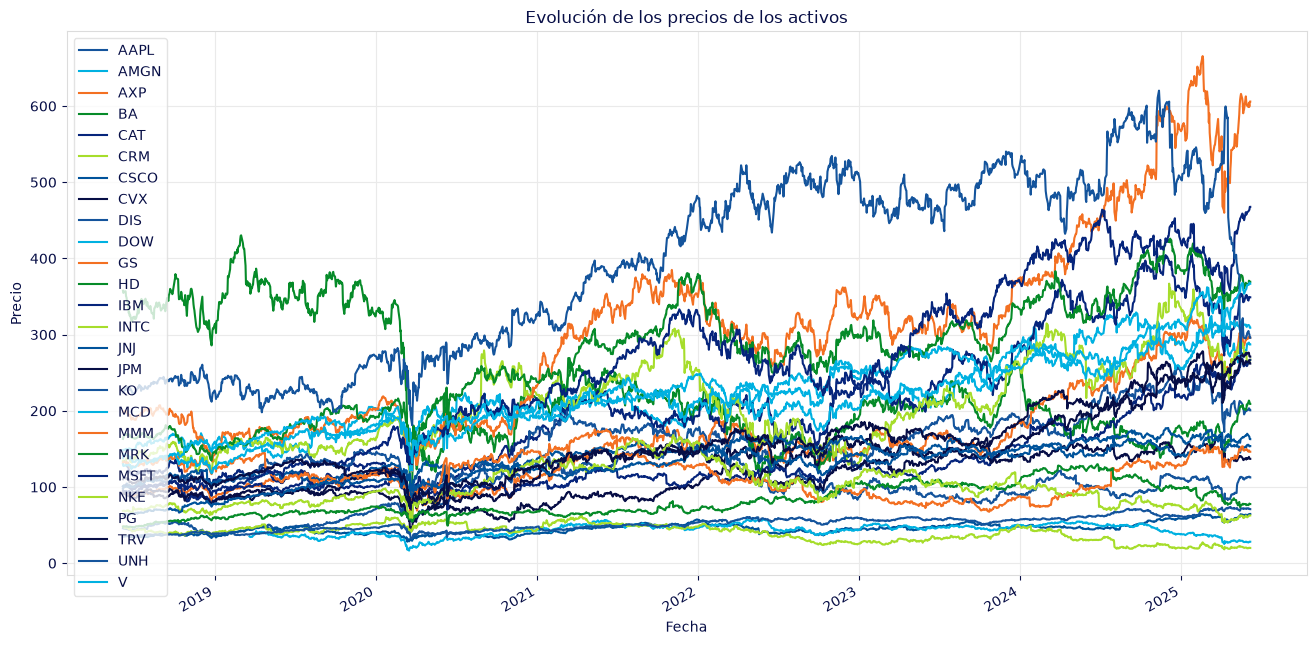

In [102]:
#Representamos los precios de los activos
datos.plot(figsize=(16, 8))

plt.title("Evolución de los precios de los activos")
plt.xlabel("Fecha")
plt.ylabel("Precio")
plt.legend()
plt.savefig(os.path.join(ruta_graficos, 'Evolución de los precios de los activos.png'.replace(' ', '_')))
plt.show()


### Conclusiones: evolución de los precios

- El gráfico en precios absolutos no sirve para comparar rentabilidades: cada activo parte de un nivel distinto (de 20-30 $ en INTC o CSCO a más de 300 $ en BA o GS al inicio), así que la altura de la línea no indica mejor o peor comportamiento.
- Se aprecia un patrón común de mercado: tendencia alcista hasta principios de 2020, caída brusca y simultánea en marzo de 2020 (shock COVID-19) y recuperación posterior. Que casi todos los activos caigan a la vez indica que existe un fuerte componente de riesgo sistemático (de mercado).
- Boeing (BA) destaca por un desplome muy superior al del resto en 2019-2020 (crisis del 737 MAX y COVID) y por no recuperar después los niveles previos.
- Se observan algunos saltos aislados (por ejemplo en 2020 y 2021) que no parecen movimientos de mercado, sino posibles errores de datos o eventos corporativos (splits, escisiones) no ajustados. Esto es relevante porque contamina las métricas de riesgo, como se verá más adelante.
- Además, DOW empieza a cotizar más tarde (escisión de DowDuPont en 2019), por lo que tiene menos observaciones que el resto.


## 4. NORMALIZACIÓN DE LOS PRECIOS

Se normalizan los precios a base 100 en el primer día para poder comparar la evolución relativa de activos que parten de precios diferentes.


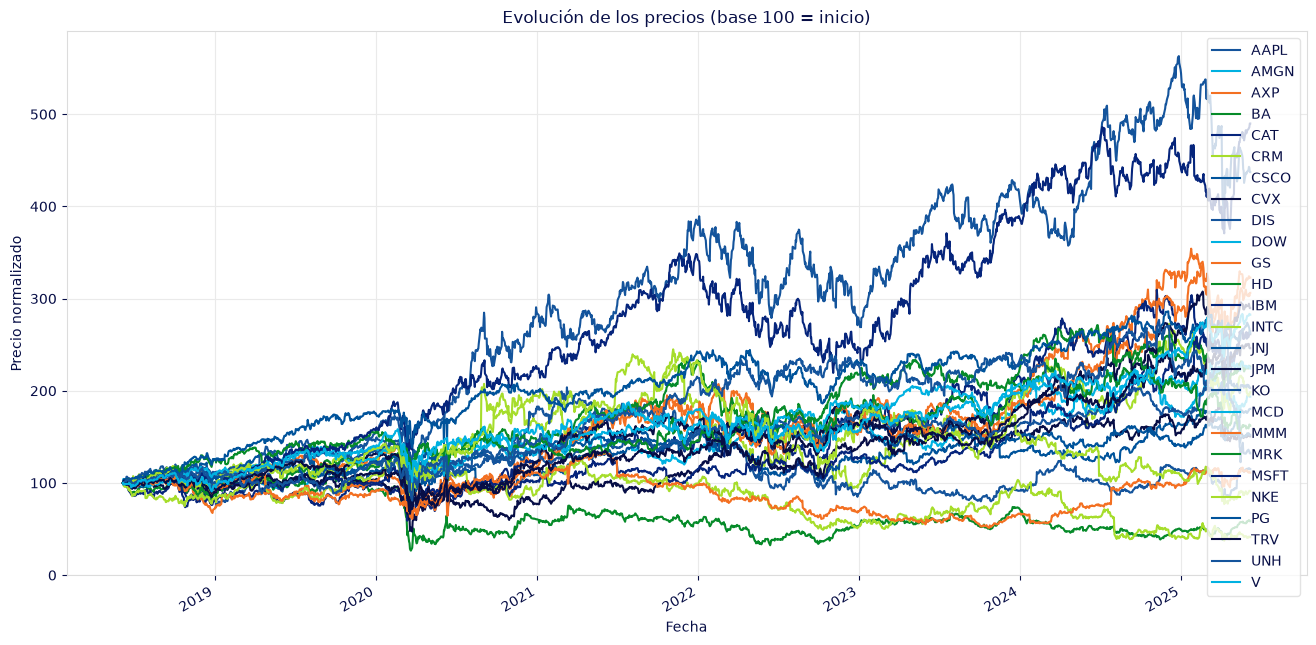

In [103]:
#Normalizamos los precios a base 100
precios_norm = datos / datos.iloc[0] * 100
precios_norm.plot(figsize=(16, 8))

plt.title("Evolución de los precios (base 100 = inicio)")
plt.xlabel("Fecha")
plt.ylabel("Precio normalizado")
plt.legend()
plt.savefig(os.path.join(ruta_graficos, 'Evolución de los precios (base 100 = inicio).png'.replace(' ', '_')))
plt.show()

###  Conclusiones: precios normalizados (base 100)

- Al partir todos de 100, ahora sí es posible comparar la rentabilidad acumulada: la mayoría de activos termina entre 150 y 350, es decir, **el periodo 2018-2025 fue claramente alcista para el mercado estadounidense en su conjunto.
- Microsoft (MSFT) es el gran ganador, con una revalorización cercana al +426 %, seguido por otros valores de calidad/crecimiento y financieros (IBM, GS, JPM, AXP). En el extremo opuesto, Intel (INTC) y Boeing (BA) terminan por debajo de 100 (pérdidas de ~-51 % y ~-39 %) y Nike (NKE) acaba prácticamente en 100: en un mercado alcista, estos tres han destruido valor frente al inversor que simplemente hubiera comprado el mercado.
- Se confirma que el efecto COVID (caída conjunta en marzo de 2020) y que los activos defensivos (JNJ, KO, PG, MCD) siguen una trayectoria más suave que los cíclicos o tecnológicos.
- La dispersión entre activos crece con el tiempo: a más horizonte, más diferencia entre "ganadores" y "perdedores", lo que subraya la importancia de la selección de activos y de la diversificación.


## 5. CÁLCULO DE RENTABILIDADES

Calculamos la rentabilidad diaria mediante el cambio porcentual entre un precio y el anterior.

También se prepara una función para calcular la rentabilidad anualizada siguiendo la estructura utilizada en clase.


In [104]:
# Rentabilidad diaria
rentabilidades = datos.pct_change()
rentabilidades.head()

Ticker,AAPL,AMGN,AXP,BA,CAT,CRM,CSCO,CVX,DIS,DOW,...,KO,MCD,MMM,MRK,MSFT,NKE,PG,TRV,UNH,V
2018-06-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-06-07,-0.002577,-0.001362,0.005051,-0.008155,-0.001406,-0.019476,-0.013782,0.029016,0.005495,NaN,...,-0.000460,0.043725,0.005935,0.000969,-0.015709,0.000134,0.018964,0.013828,0.001327,-0.017904
2018-06-08,-0.010284,0.005456,-0.004730,0.002632,-0.006206,0.004665,-0.003895,-0.004096,0.014736,NaN,...,0.011740,-0.003363,0.007412,0.009518,0.007435,0.001873,0.018743,0.011944,0.006828,0.006725
2018-06-11,-0.001828,0.001682,0.001980,0.003897,0.006470,0.003370,0.004830,0.008858,0.003558,NaN,...,0.004096,-0.014327,-0.007116,-0.003995,-0.005707,-0.004139,0.004535,-0.006244,0.012366,-0.002375
2018-06-12,0.006068,0.002492,-0.004644,-0.000863,0.014745,0.017017,0.005722,-0.003763,-0.000192,NaN,...,0.006345,0.001441,-0.000975,0.001765,0.002573,-0.002413,-0.003740,-0.007050,-0.000788,0.002083


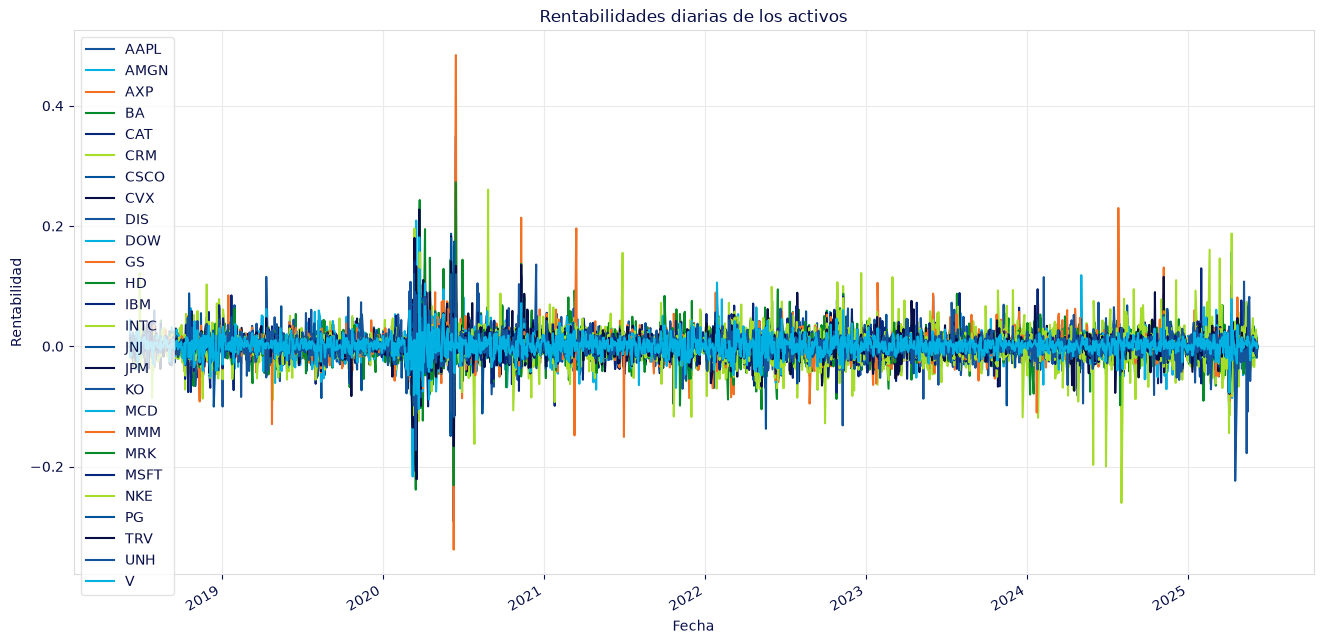

In [105]:
# Representamos las rentabilidades diarias
rentabilidades.plot(figsize=(16, 8))

plt.title("Rentabilidades diarias de los activos")
plt.xlabel("Fecha")
plt.ylabel("Rentabilidad")
plt.legend()
plt.savefig(os.path.join(ruta_graficos, ('Rentabilidades diarias de los activos' + '.png').replace(' ', '_')))
plt.show()

###  Conclusiones: rentabilidades diarias

- Las rentabilidades diarias oscilan alrededor de cero y de forma estable, como es típico en series financieras (comportamiento aproximadamente estacionario en media).
- Se observa claramente el fenómeno de agrupamiento de volatilidad (volatility clustering): los movimientos son mucho más amplios en marzo-abril de 2020 y más tranquilos en 2021-2024. Es decir, los periodos de alta volatilidad tienden a ir seguidos de más volatilidad, lo que justifica medir el riesgo en ventanas temporales y no con un único valor.
- Hay un dato claramente anómalo en AAPL a mediados de 2020: una rentabilidad cercana a +300 % seguida de otra de aproximadamente -75 %. Ningún activo de gran capitalización se comporta así de un día para otro; lo más probable es un error de datos o un ajuste por split mal tratado, no un movimiento real de mercado.
- Ese único dato distorsiona la escala del gráfico y, como veremos, inflará artificialmente la volatilidad y el drawdown de AAPL. En un análisis riguroso habría que limpiarlo antes de sacar conclusiones sobre ese activo.
- También se aprecian picos en otros valores ( un salto de alrededor del +19 % en CAT en junio de 2018, inusual para un valor industrial), que conviene tratar con cautela.


In [106]:
# Función para calcular rentabilidades anualizadas
def rtb_anualizada(tipo, n, p0, p1, dias_habiles):

    if tipo == 'd':
        r = (p1 - p0) / p0
        return ((1 + r) ** (dias_habiles / n)) - 1

    if tipo == 'm':
        r = (p1 - p0) / p0
        return ((1 + r) ** (12 / n)) - 1

    if tipo == 'y':
        r = (p1 - p0) / p0
        return ((1 + r) ** (1 / n)) - 1

    else:
        print("Por favor, introduzca 'd', 'm' o 'y' en el tipo")
        return

In [107]:
# Calculamos las principales rentabilidades de cada activo
def calcular_rentabilidades(precios, dias_habiles=252):
    resultados = []

    for activo in precios.columns:

        serie = precios[activo].dropna()
        rent_diarias = serie.pct_change().dropna()
        rent_media = rent_diarias.mean()
        rent_activa = (serie.iloc[-1] - serie.iloc[0]) / serie.iloc[0]
        n = len(serie)
        rent_anual = rtb_anualizada('d', n, serie.iloc[0], serie.iloc[-1], dias_habiles)
        resultados.append([activo, rent_media, rent_activa, rent_anual])

    return pd.DataFrame(resultados, columns=["Activo", "Rentabilidad media diaria", "Rentabilidad acumulada", "Rentabilidad anualizada"]).set_index("Activo")

In [108]:
# Tabla de rentabilidades
tabla_rentabilidades = calcular_rentabilidades(datos)
tabla_rentabilidades.style.format("{:.2%}")

,Rentabilidad media diaria,Rentabilidad acumulada,Rentabilidad anualizada
Activo,,,
AAPL,0.10%,337.19%,23.50%
AMGN,0.05%,93.59%,9.91%
AXP,0.09%,222.70%,18.25%
BA,0.01%,-41.55%,-7.40%
CAT,0.08%,161.30%,14.73%
CRM,0.07%,98.49%,10.31%
CSCO,0.05%,80.41%,8.81%
CVX,0.04%,50.46%,6.02%
DIS,0.03%,14.95%,2.01%


## 6. CÁLCULO DE LA VOLATILIDAD

Calculamos la desviación típica diaria y la volatilidad anualizada.

La anualización se realiza utilizando 252 días de cotización, siguiendo el procedimiento utilizado en clase.


In [109]:
# Función para calcular la volatilidad anualizada
def volatilidad_anualizada(precios, dias_habiles=252):
    rentabilidades = precios.pct_change().dropna()
    desviacion = rentabilidades.std(ddof=0)
    return desviacion * np.sqrt(dias_habiles)

In [110]:
# Calculamos la volatilidad de todos los activos
volatilidades = {}
for activo in datos.columns:
    volatilidades[activo] = volatilidad_anualizada(datos[activo])

tabla_volatilidad = pd.DataFrame.from_dict(volatilidades, orient="index", columns=["Volatilidad anualizada"])
tabla_volatilidad.style.format("{:.2%}")

,Volatilidad anualizada
AAPL,31.67%
AMGN,25.34%
AXP,34.30%
BA,46.51%
CAT,33.04%
CRM,37.81%
CSCO,28.04%
CVX,32.51%
DIS,31.94%
DOW,36.63%


## 7. VOLATILIDAD EN VENTANAS TEMPORALES

Calculamos la secuencia de volatilidades utilizando una ventana móvil.

Se utiliza una ventana de 30 días, como en el ejercicio de referencia de clase.


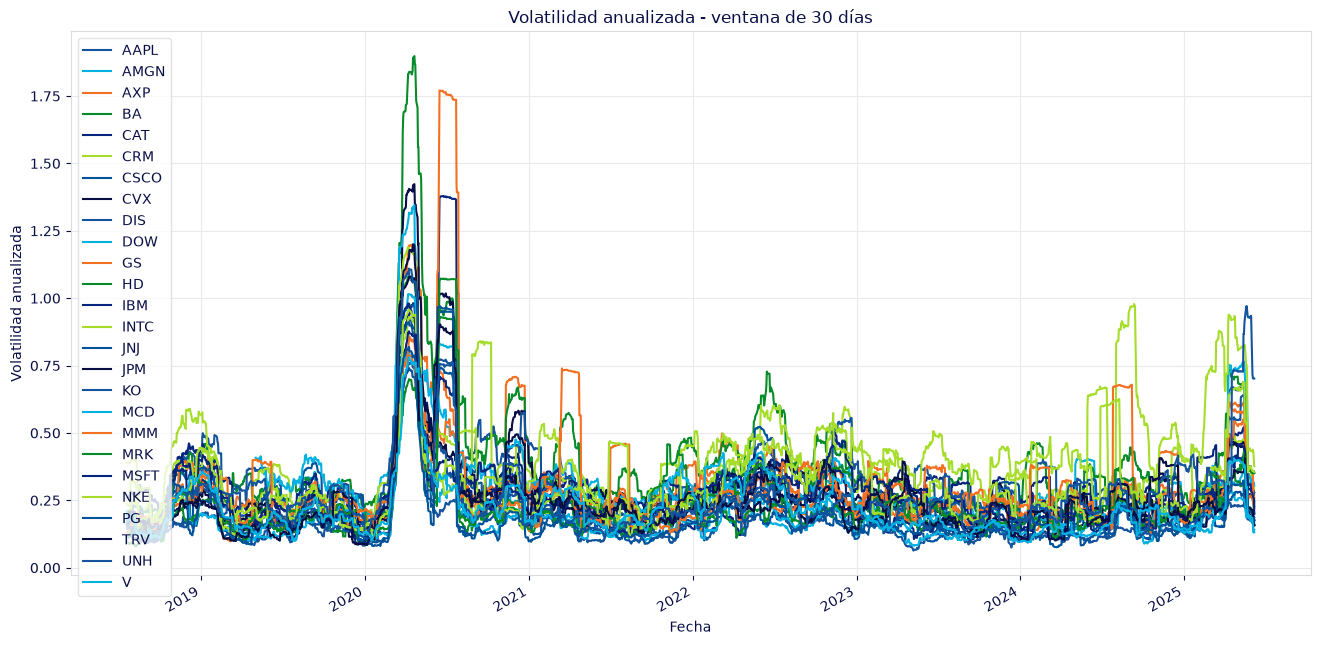

In [111]:
# Volatilidad anualizada a 30 días
volatilidad_30 = rentabilidades.rolling(30).std(ddof=0) * np.sqrt(252)
volatilidad_30.plot(figsize=(16, 8))

plt.title("Volatilidad anualizada - ventana de 30 días")
plt.xlabel("Fecha")
plt.ylabel("Volatilidad anualizada")
plt.legend()
plt.savefig(os.path.join(ruta_graficos, ('Volatilidad anualizada ventana de 30 días' + '.png').replace(' ', '_')))
plt.show()

###  Conclusiones: volatilidad anualizada a 30 días

- La volatilidad no es constante en el tiempo: en condiciones normales la mayoría de activos se mueve en el rango de ~15-40 % anualizado, pero en marzo-abril de 2020 se dispara hasta el 100-200 %, en un episodio de crisis sistémica en el que todos los activos se vuelven más arriesgados a la vez.
- Después de 2020 la volatilidad vuelve a niveles bajos (mean reversion de la volatilidad), con repuntes moderados puntuales (2022, por la subida de tipos y la inflación, y abril de 2025).
- El pico de AAPL (~900 %) no es real: es el reflejo de la rentabilidad atípica detectada antes (error de datos) y se mantiene 30 días porque la ventana móvil arrastra ese dato. Otros picos aislados por encima del 200 % fuera de la crisis COVID (p. ej. en series como MMM o DIS) también hay que tomarlos con cautela, ya que probablemente se deban a eventos corporativos o datos erróneos.
- Las interrupciones visibles en el gráfico (principios de 2021) corresponden a datos faltantes (NaN), que la ventana móvil propaga.
- Implicación financiera: usar una única volatilidad histórica para todo el periodo infravalora el riesgo en épocas de crisis y lo sobrevalora en épocas de calma; para gestionar riesgo es preferible un enfoque dinámico.


## 8. RATIO DE SHARPE

El ratio de Sharpe se calcula como:

$S_h = \frac{r-r_f}{\sigma}$

Para el cálculo se utilizará la rentabilidad anualizada y la volatilidad anualizada.


In [112]:
# Tipo de interés libre de riesgo
rf = 0.0

# Función para calcular el ratio de Sharpe
def ratio_sharpe(precios, rf=0.0, dias_habiles=252):

    serie = precios.dropna()
    rent_anual = rtb_anualizada('d', len(serie), serie.iloc[0], serie.iloc[-1], dias_habiles)
    vol_anual = volatilidad_anualizada(serie, dias_habiles)
    return (rent_anual - rf) / vol_anual

In [113]:
# Calculamos el ratio de Sharpe para todos los activos
sharpe = {}

for activo in datos.columns:
    sharpe[activo] = ratio_sharpe(datos[activo], rf)

tabla_sharpe = pd.DataFrame.from_dict(sharpe, orient="index", columns=["Sharpe"])
tabla_sharpe

,Sharpe
AAPL,0.742263
AMGN,0.391209
AXP,0.532102
BA,-0.159027
CAT,0.445985
CRM,0.272600
CSCO,0.314170
CVX,0.185196
DIS,0.063028
DOW,-0.095393


## 9. RATIO DE SORTINO

El ratio de Sortino es similar al Sharpe, pero utiliza únicamente la volatilidad asociada a rentabilidades negativas.

Se prepara como métrica adicional de riesgo para completar el análisis solicitado.


In [114]:
# Función para calcular el ratio de Sortino
def ratio_sortino(precios, rf=0.0, dias_habiles=252):
    serie = precios.dropna()
    rent_diarias = serie.pct_change().dropna()
    rent_anual = rtb_anualizada('d', len(serie), serie.iloc[0], serie.iloc[-1], dias_habiles)
    rent_rf_diaria = (1 + rf) ** (1 / dias_habiles) - 1
    rent_negativas = rent_diarias[rent_diarias < rent_rf_diaria]
    downside = np.sqrt(((rent_negativas - rent_rf_diaria) ** 2).mean()) * np.sqrt(dias_habiles)

    return (rent_anual - rf) / downside

In [115]:
# Calculamos el ratio de Sortino
sortino = {}

for activo in datos.columns:
    sortino[activo] = ratio_sortino(datos[activo], rf)

tabla_sortino = pd.DataFrame.from_dict(sortino, orient="index", columns=["Sortino"])
tabla_sortino

,Sortino
AAPL,0.738240
AMGN,0.410812
AXP,0.550134
BA,-0.164849
CAT,0.444181
CRM,0.273300
CSCO,0.298383
CVX,0.178553
DIS,0.065665
DOW,-0.094093


## 10. DRAWDOWN MÁXIMO

El drawdown mide la caída de un activo desde un máximo anterior.

$Drawdown_i = \frac{p_i}{p_{max}} - 1$

Calculamos también el máximo drawdown dentro de una ventana temporal de 252 días.


In [116]:
# Función para calcular el drawdown
def drawdown(precios, ventana=252, plot=0):

    precios = precios.dropna()
    roll_max = precios.rolling(window=ventana, min_periods=1).max()
    daily_draw_down = precios / roll_max - 1

    max_daily_draw_down = daily_draw_down.rolling(window=ventana, min_periods=1).min()
    if plot == 1:
        fig, ax = plt.subplots(figsize=(16, 8))
        ax.plot(daily_draw_down.index, daily_draw_down, label="Daily drawdown", color=paleta_bbva["azul_logotipo"])
        ax.plot(max_daily_draw_down.index, max_daily_draw_down, label="Maximum drawdown in time window", color=paleta_bbva["naranja_alerta"])
        ax.legend()
        plt.show()

    return daily_draw_down, max_daily_draw_down

In [117]:
# Calculamos el drawdown máximo de cada activo
drawdowns_maximos = {}

for activo in datos.columns:
    daily_draw_down, max_daily_draw_down = drawdown(datos[activo], ventana=252)
    drawdowns_maximos[activo] = max_daily_draw_down.min()

tabla_drawdown = pd.DataFrame.from_dict(drawdowns_maximos, orient="index", columns=["Drawdown máximo"])
tabla_drawdown.style.format("{:.2%}")

,Drawdown máximo
AAPL,-38.57%
AMGN,-24.86%
AXP,-49.64%
BA,-75.42%
CAT,-40.34%
CRM,-54.91%
CSCO,-41.95%
CVX,-55.77%
DIS,-50.60%
DOW,-60.87%


In [118]:
if not os.path.exists(os.path.join(ruta_graficos, 'DRAWDOWN')):
    os.makedirs(os.path.join(ruta_graficos, 'DRAWDOWN')) 

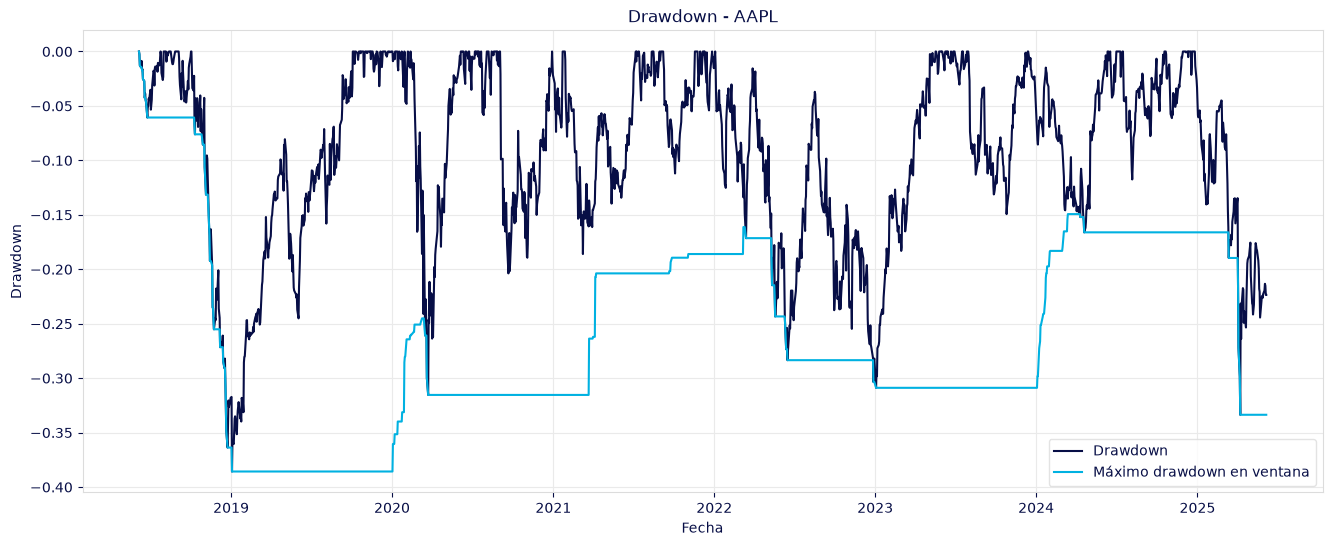

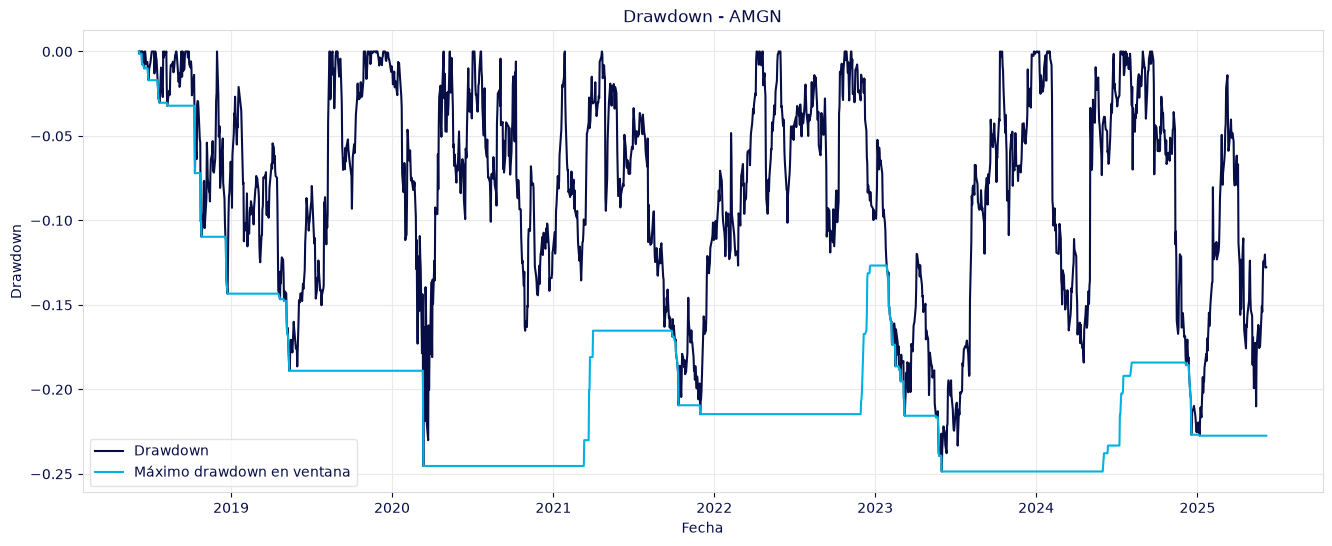

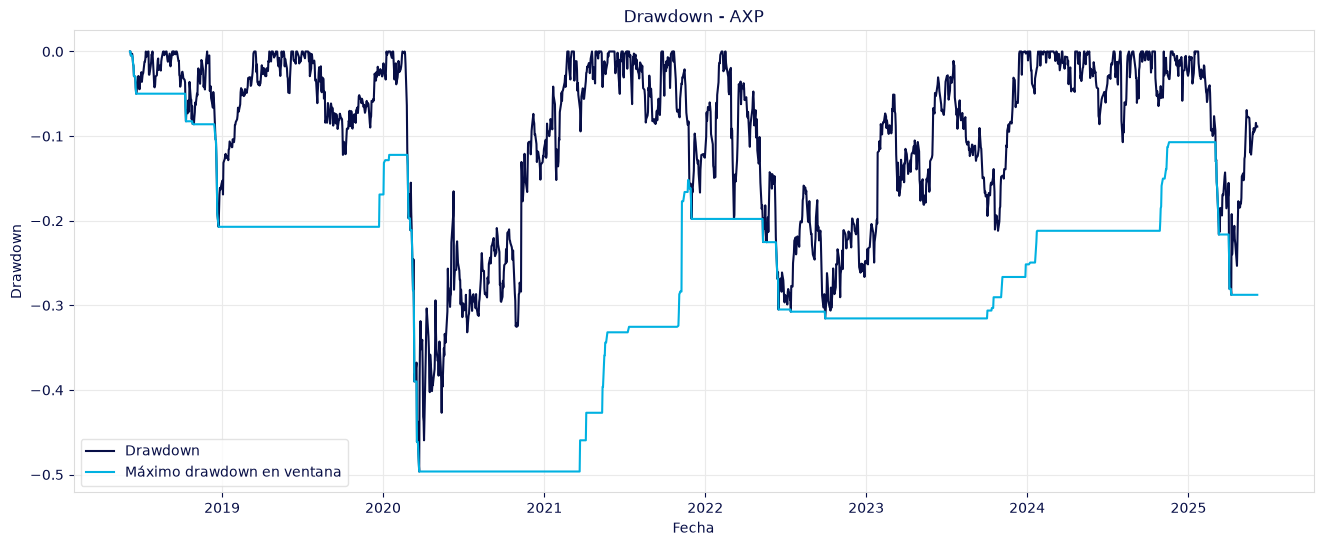

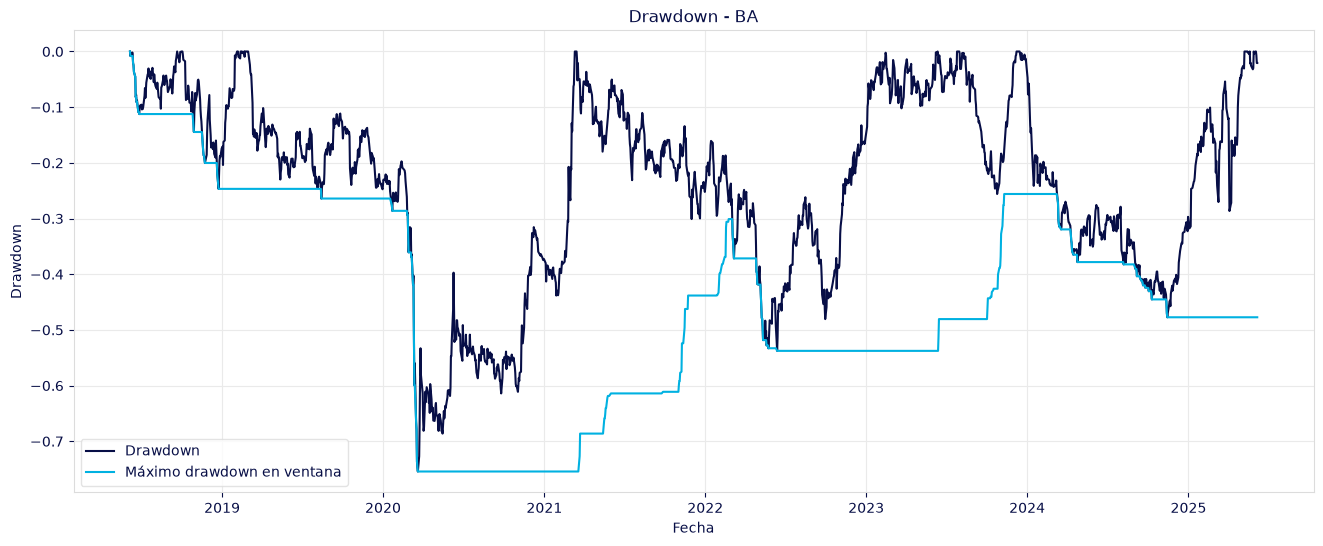

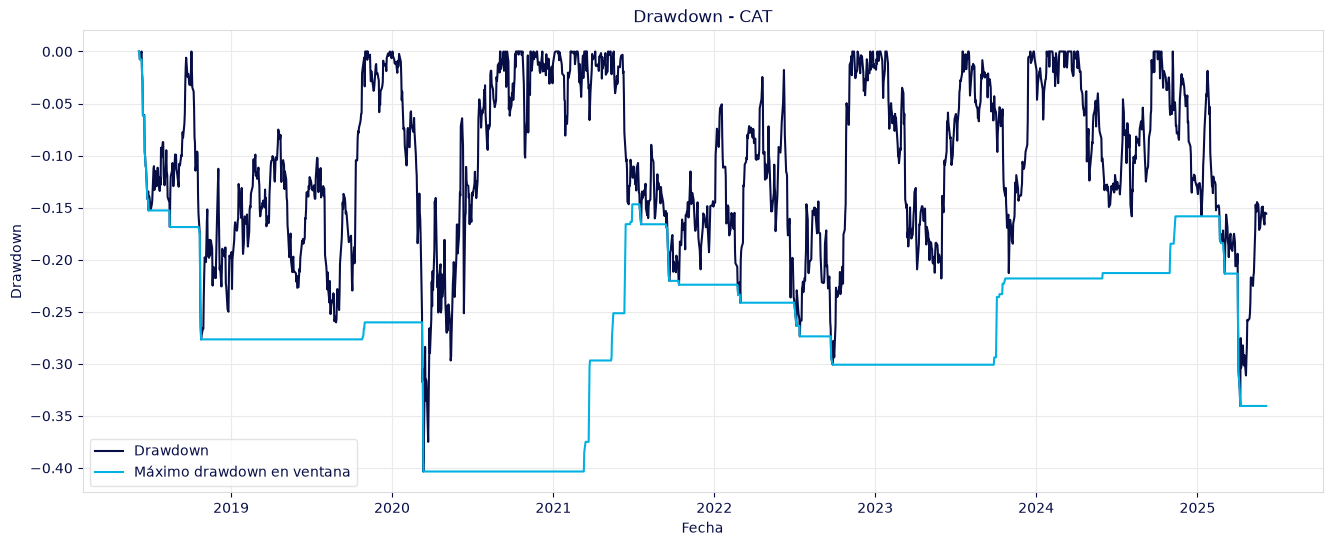

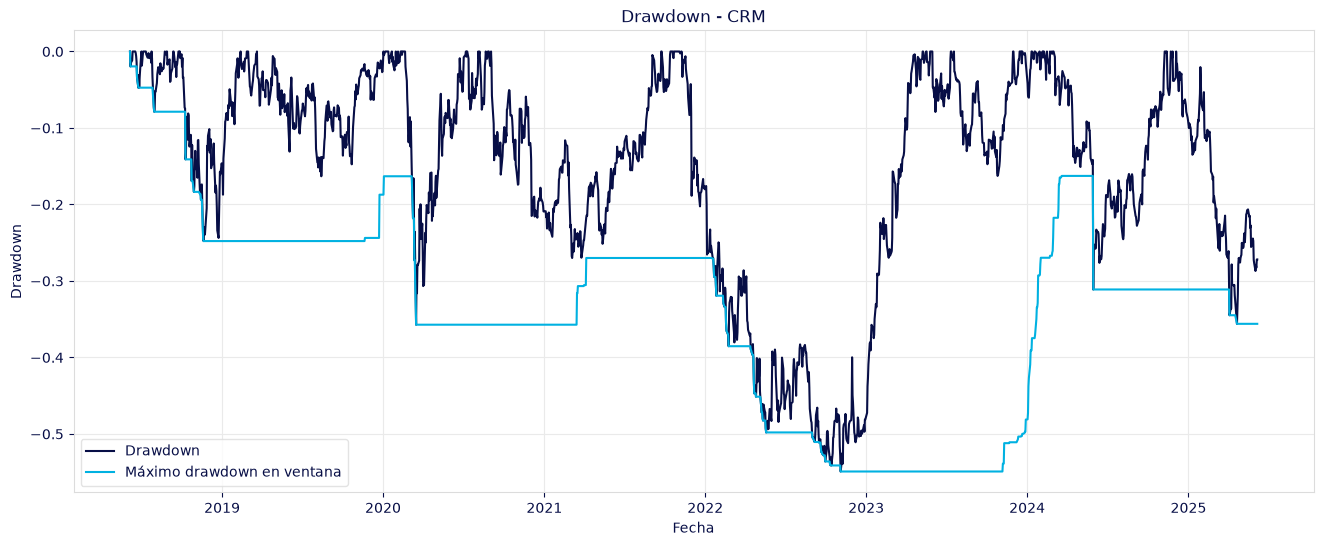

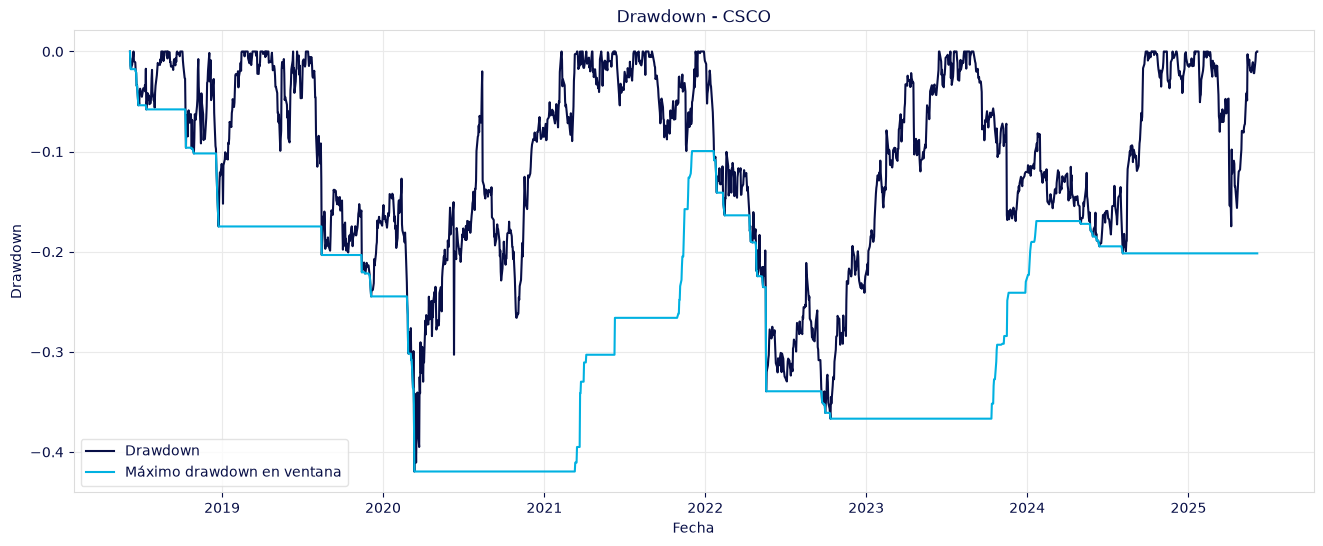

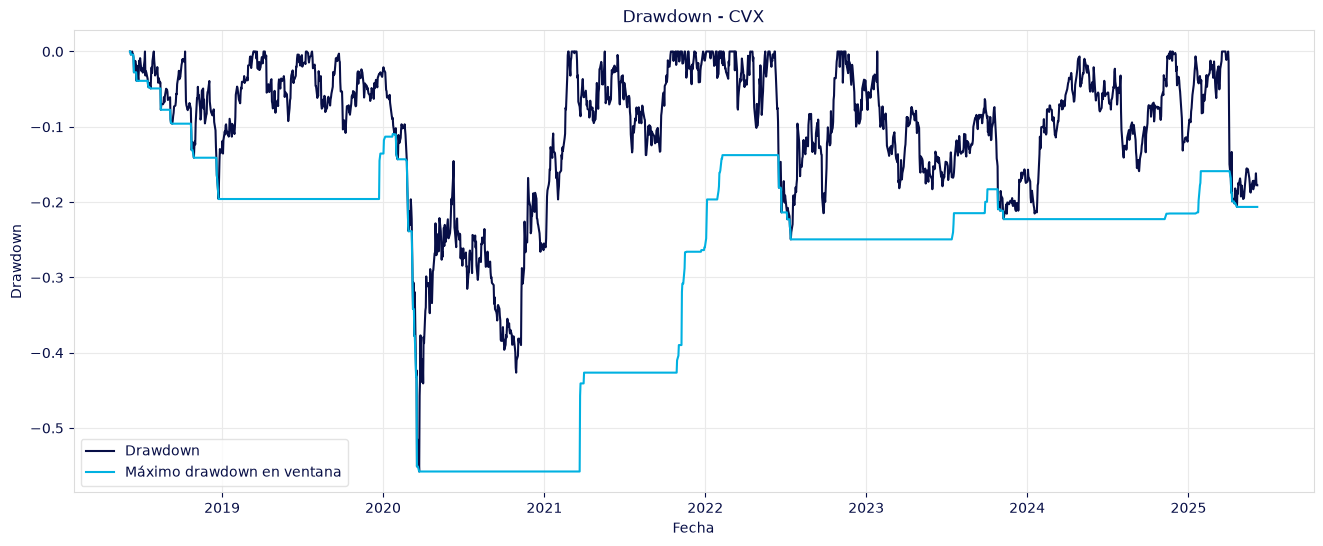

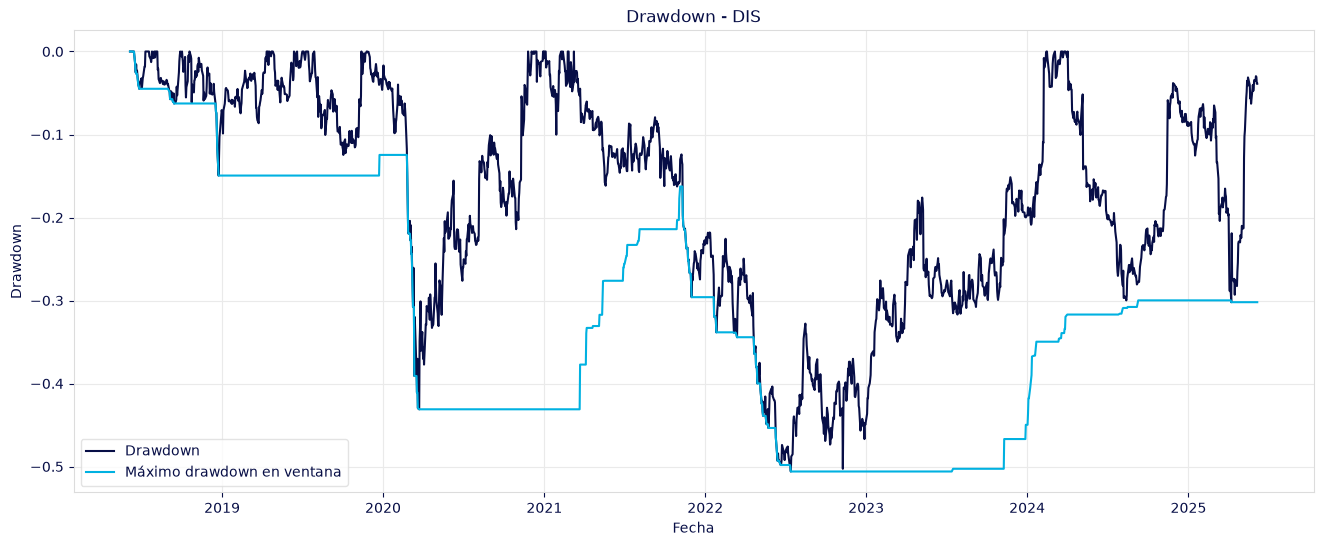

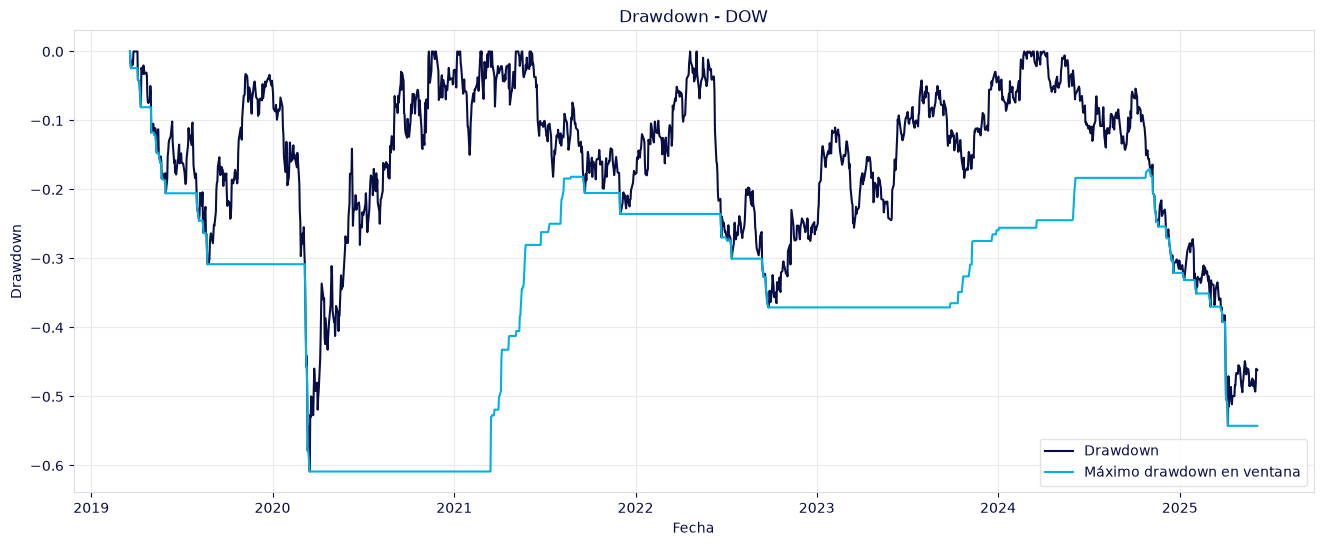

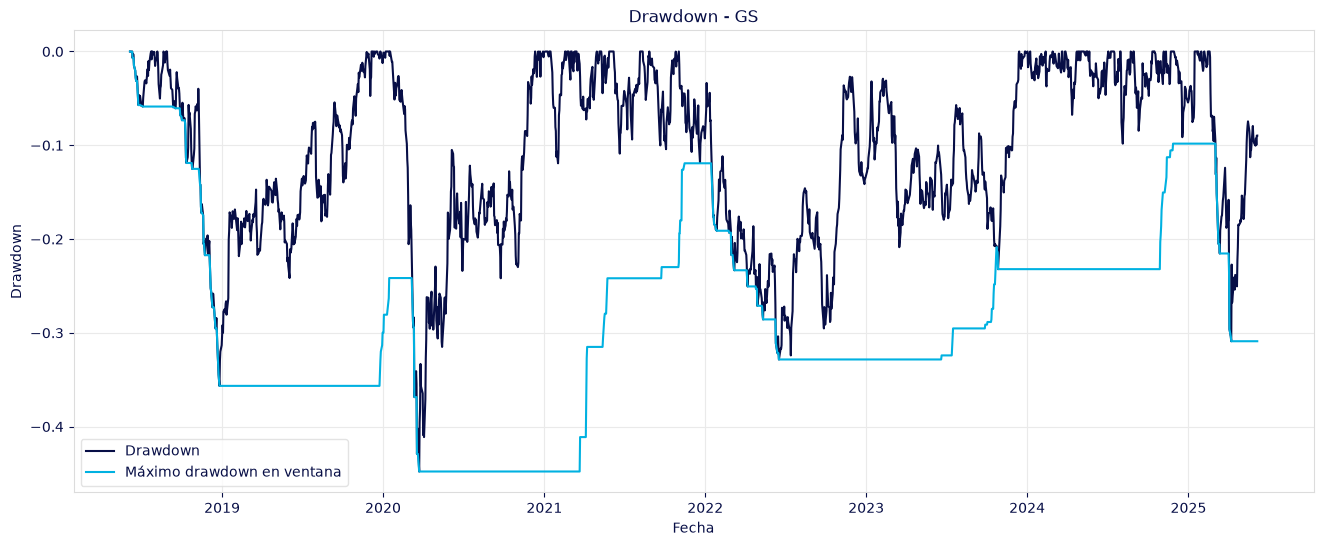

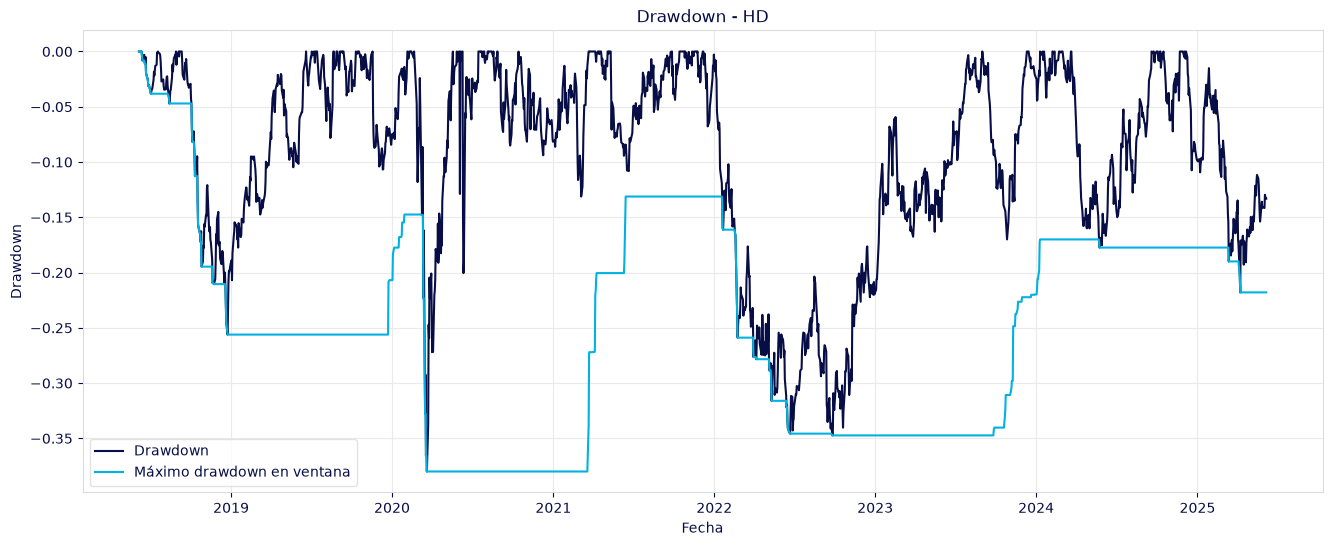

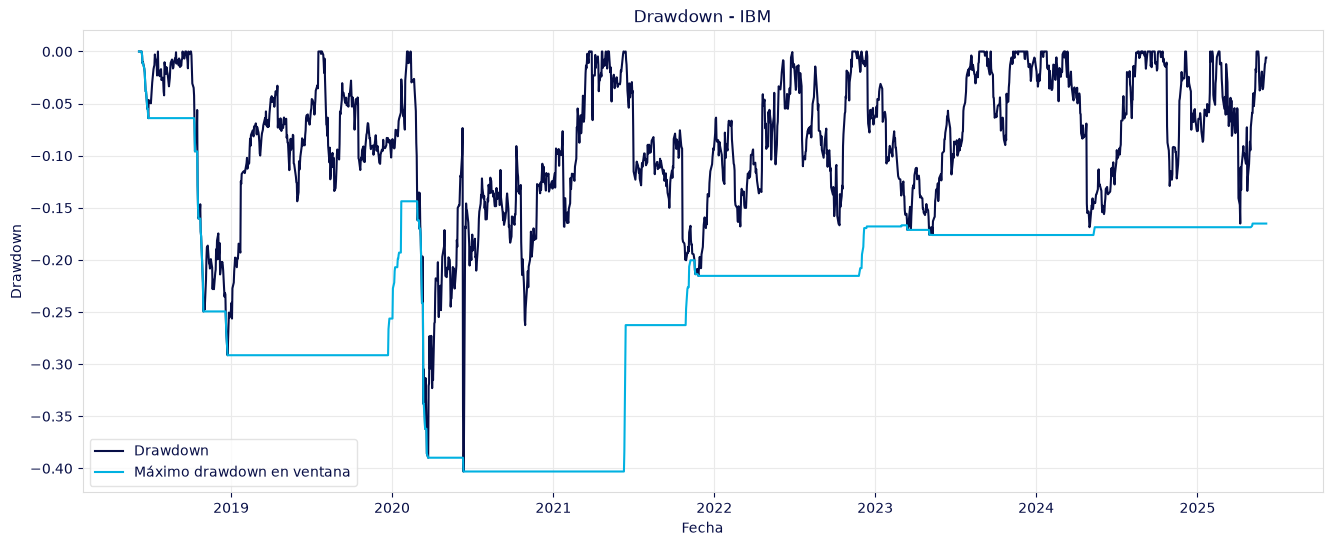

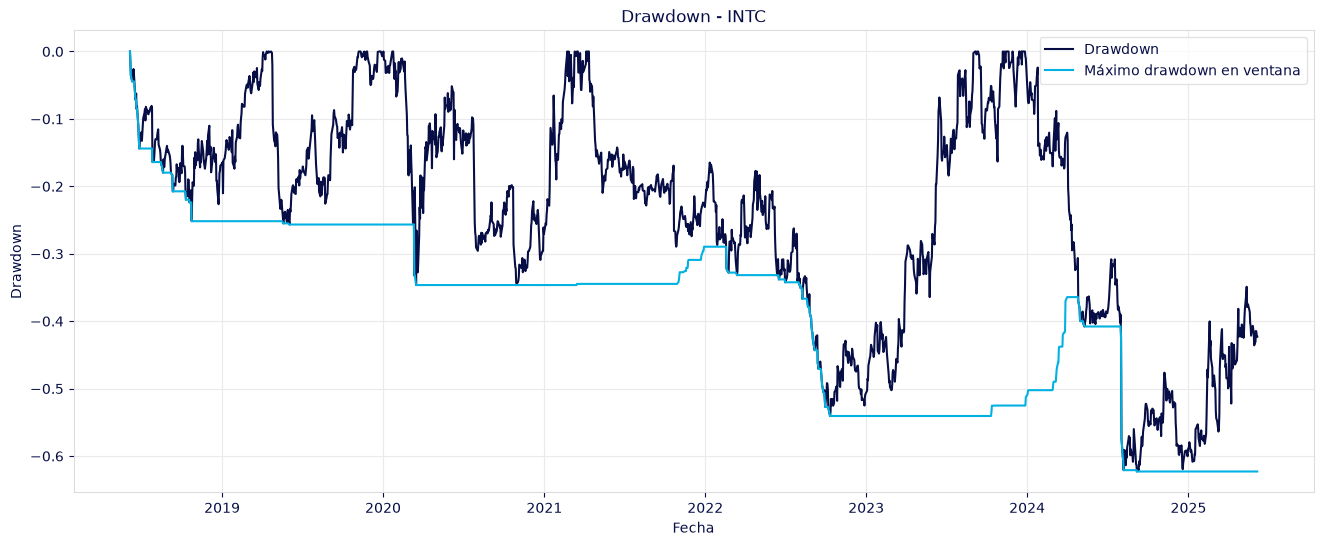

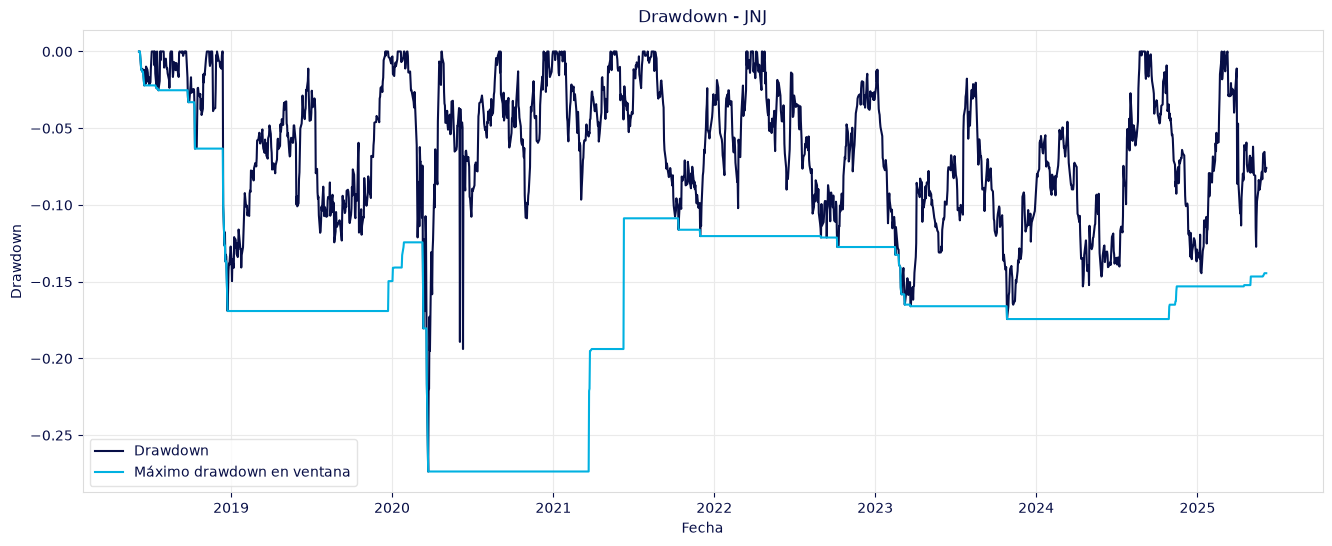

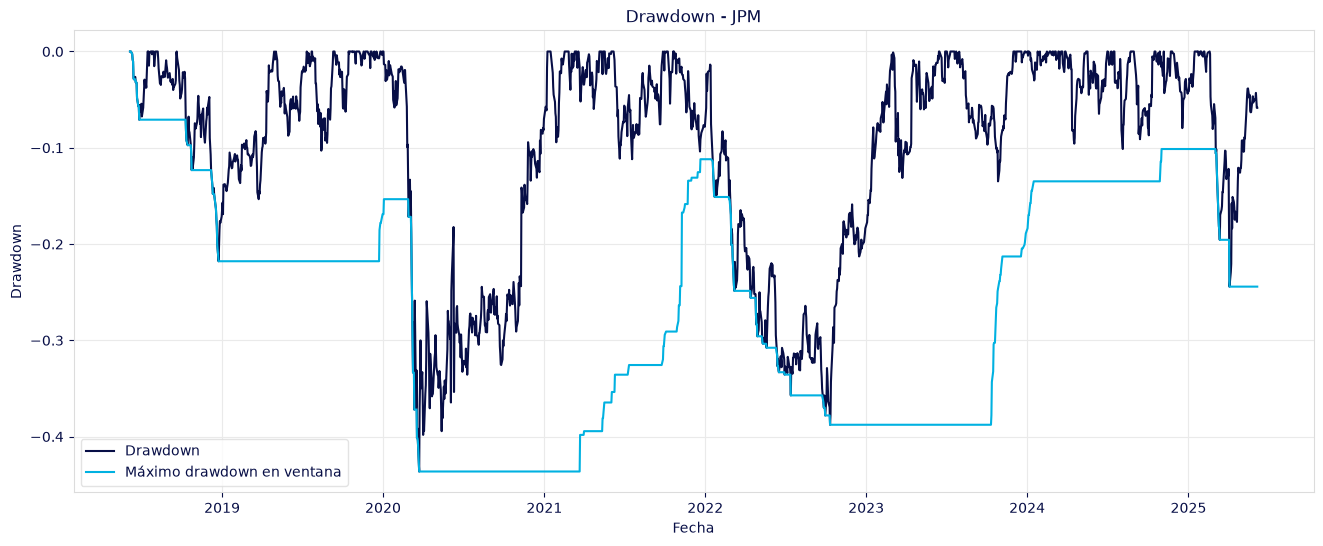

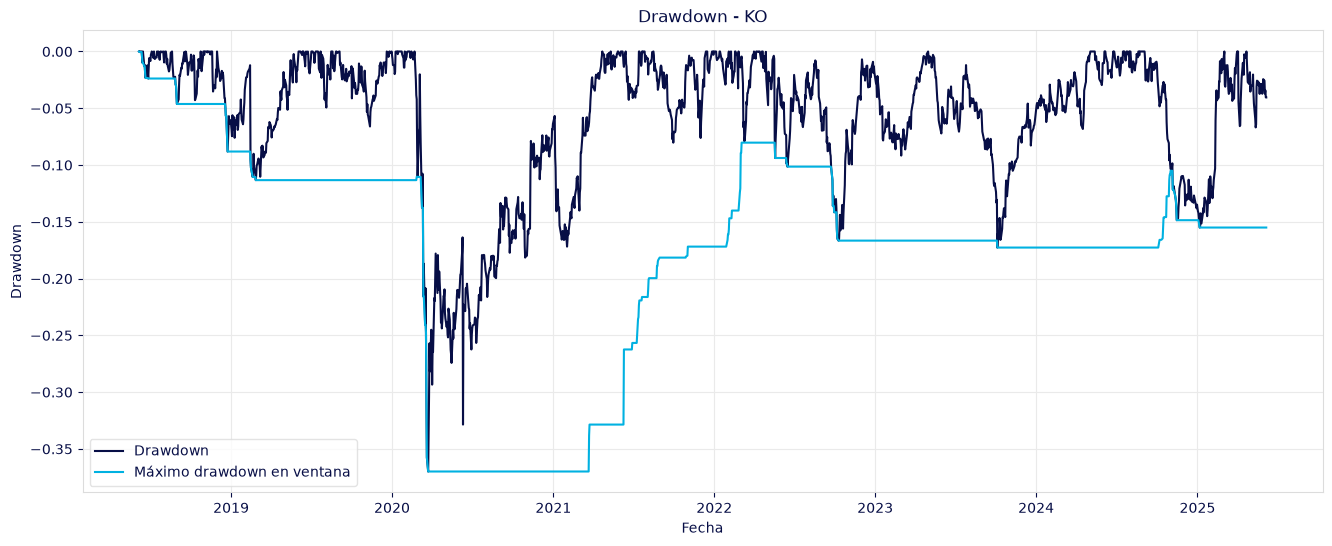

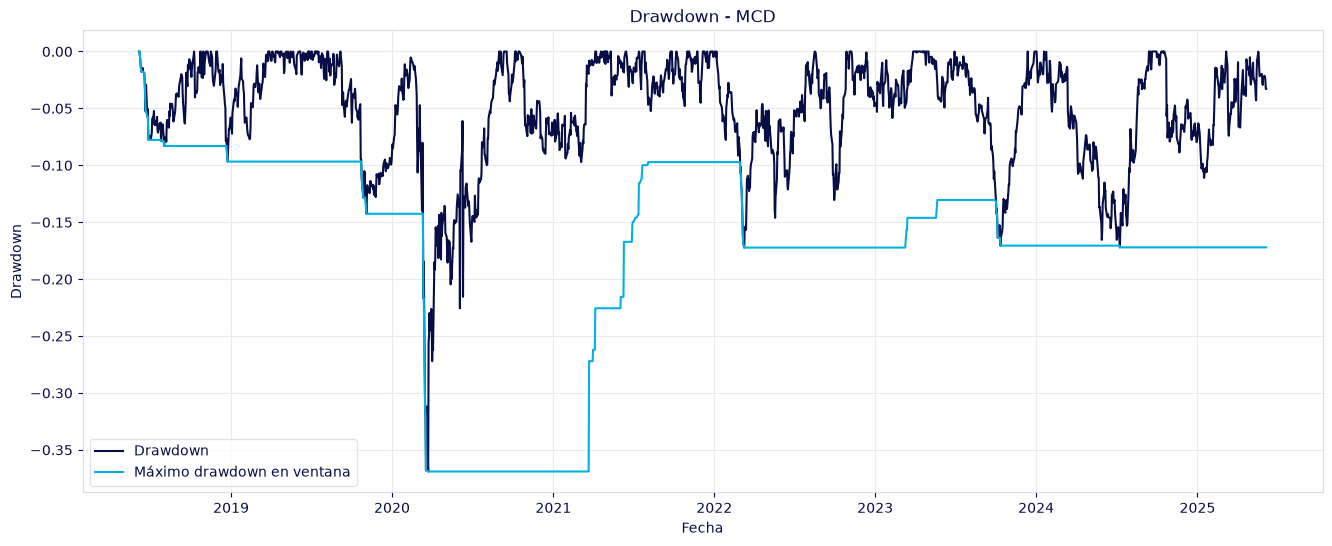

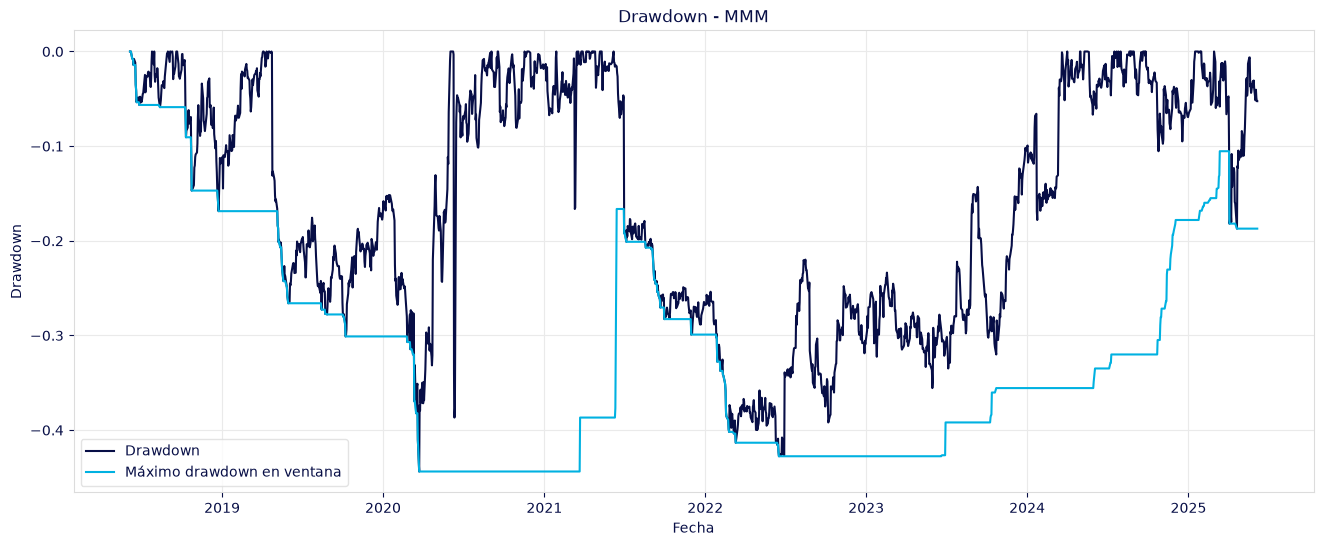

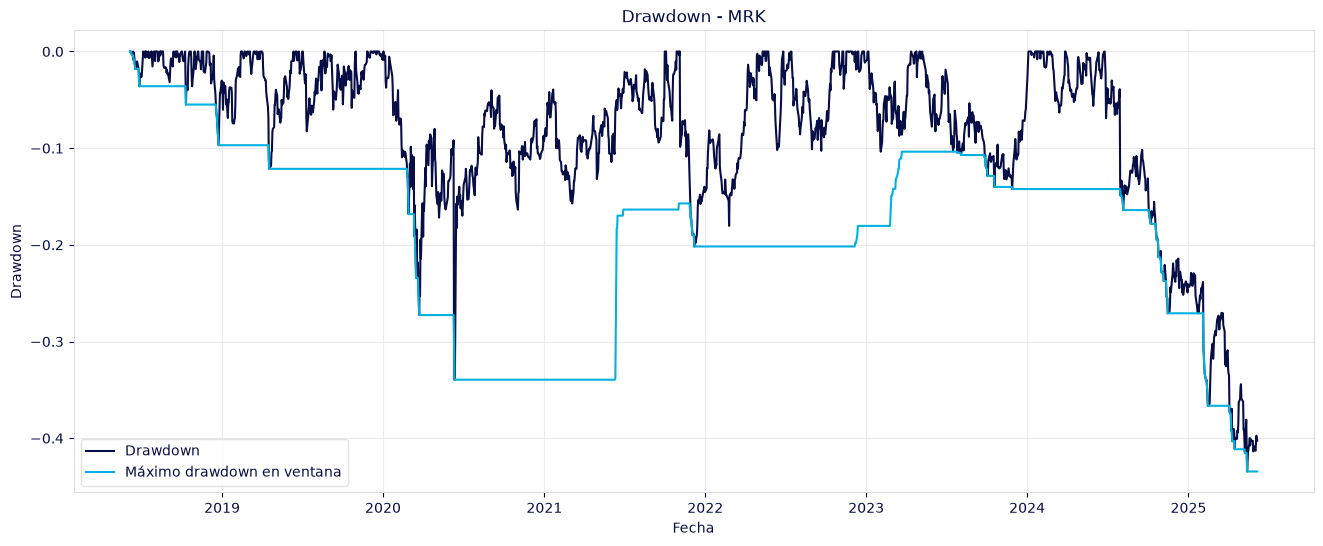

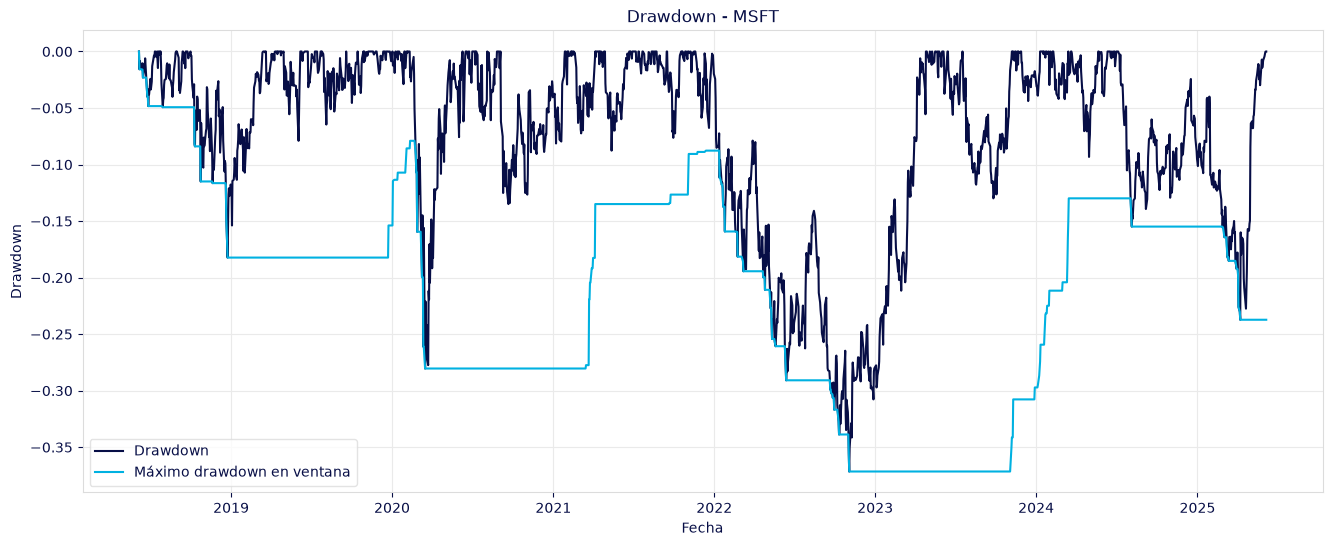

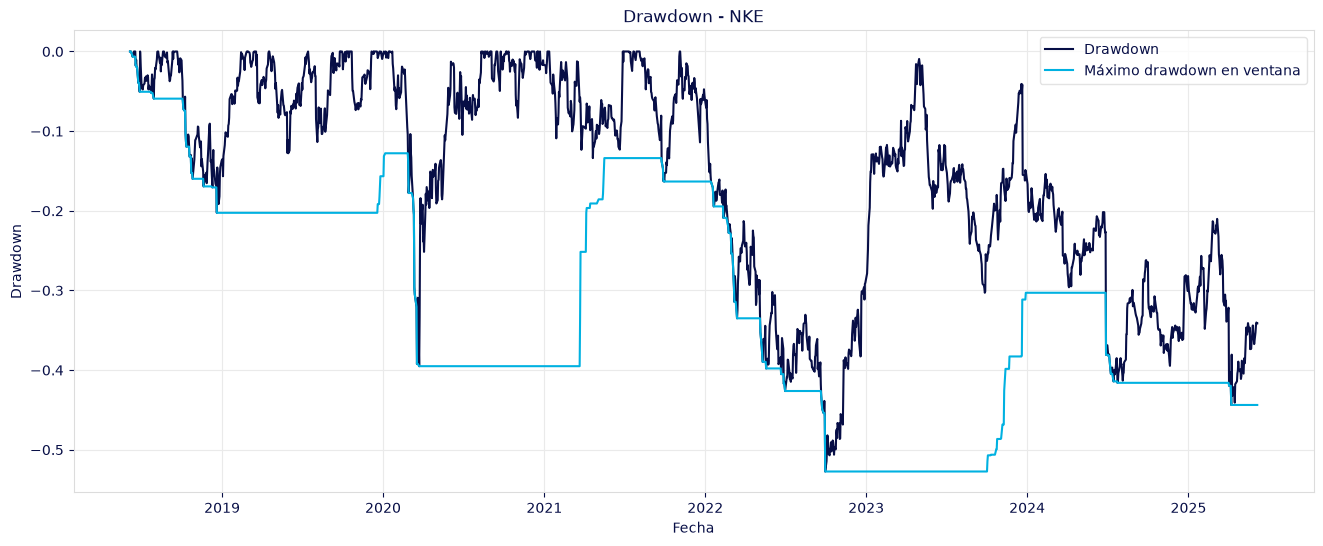

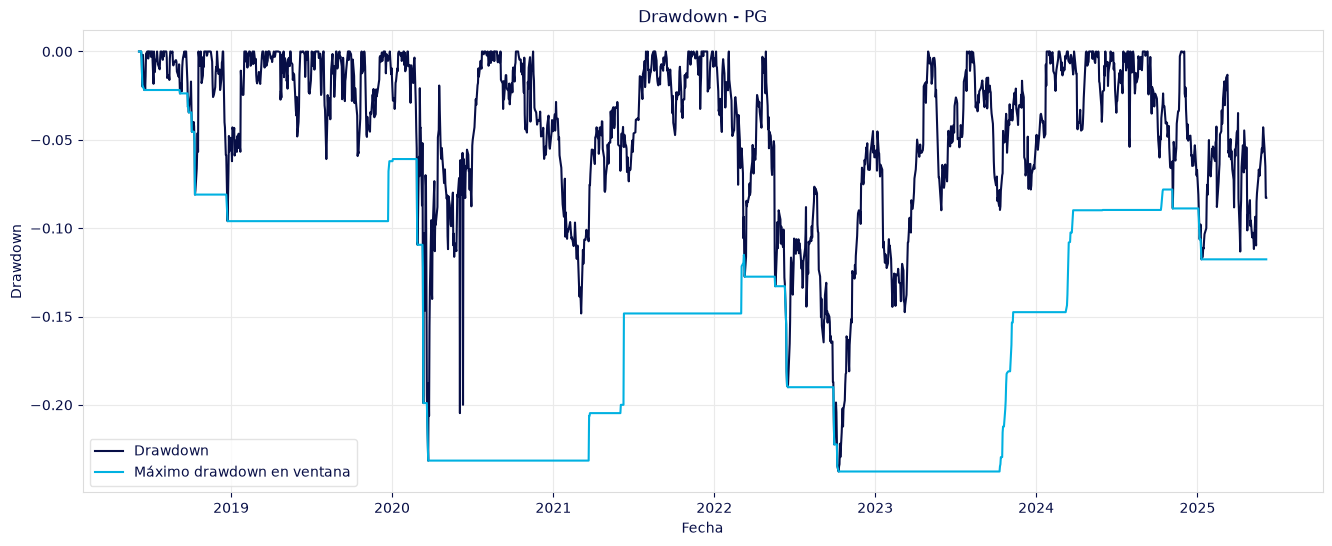

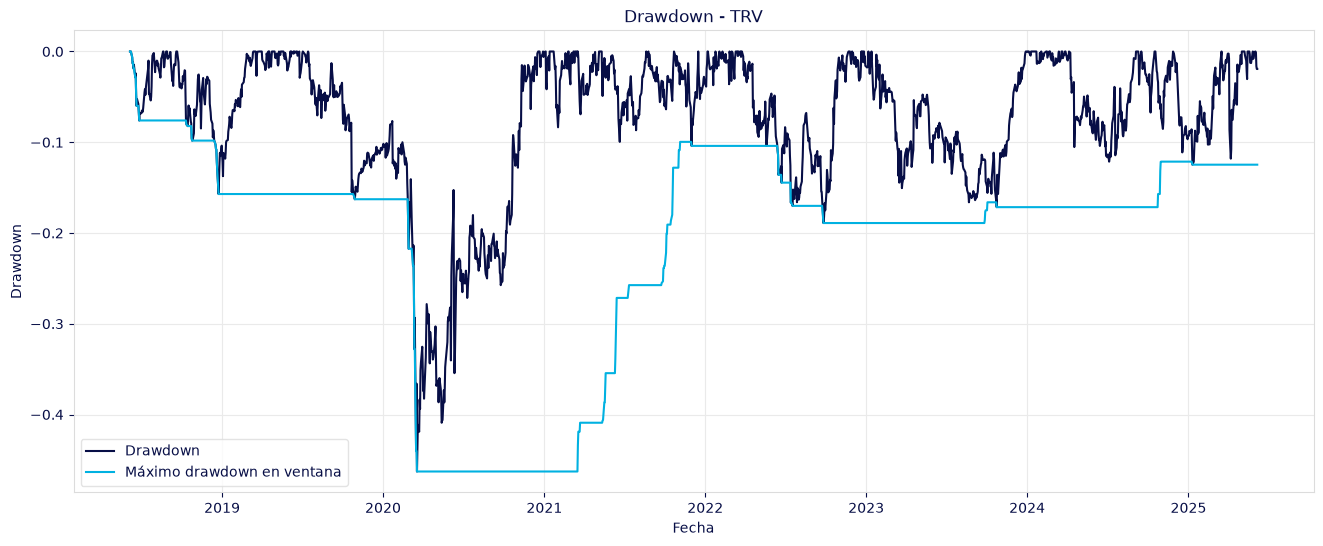

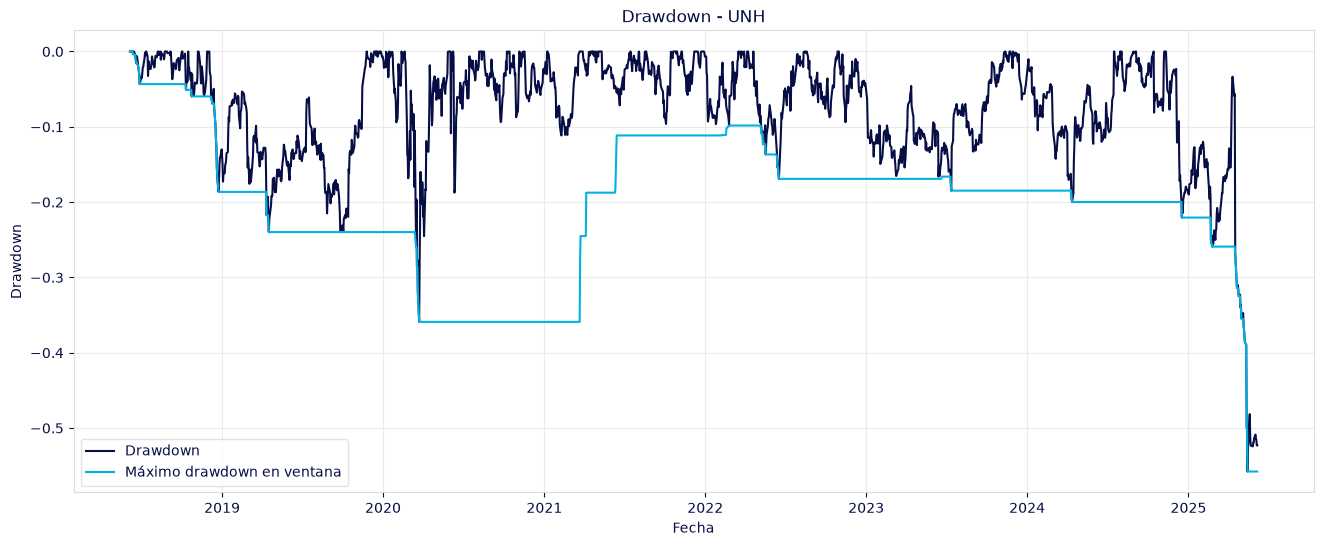

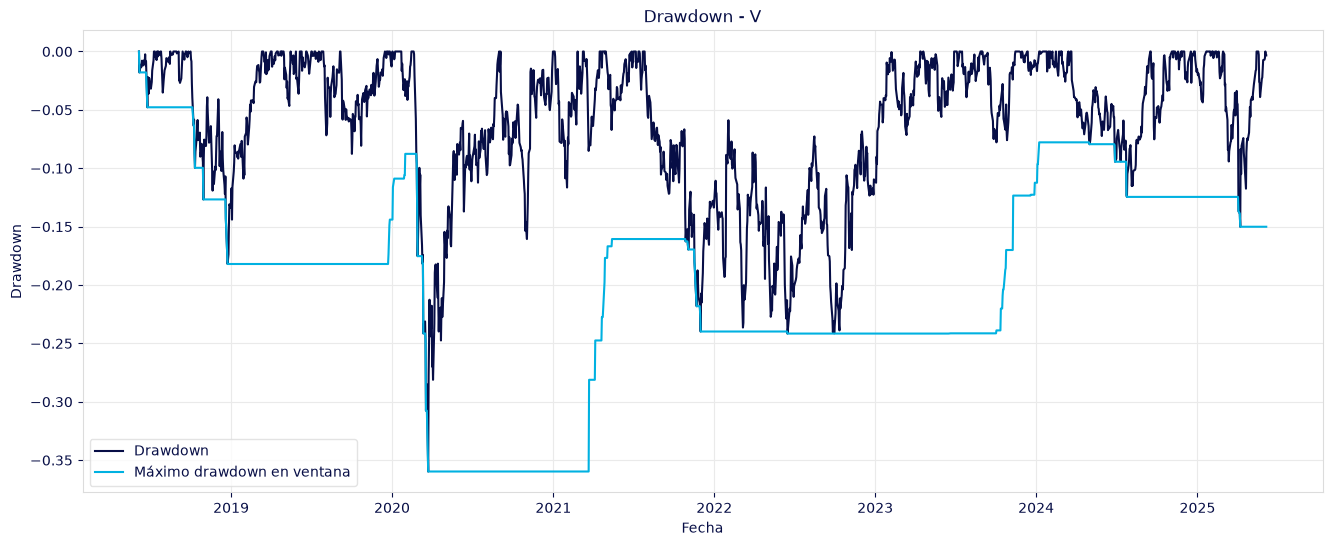

In [119]:
# Ejemplo de representación del drawdown de todos los activos
for activo in datos.columns:
    daily_draw_down, max_daily_draw_down = drawdown(datos[activo], ventana=252)

    plt.figure(figsize=(16, 6))
    plt.plot(daily_draw_down.index, daily_draw_down, label="Drawdown", color=paleta_bbva["azul_profundo_texto"])
    plt.plot(max_daily_draw_down.index, max_daily_draw_down, label="Máximo drawdown en ventana", color=paleta_bbva["azul_celeste_aqua"])

    plt.title("Drawdown - " + str(activo))
    plt.xlabel("Fecha")
    plt.ylabel("Drawdown")
    plt.legend()
    plt.savefig(os.path.join(ruta_graficos, 'DRAWDOWN', ("Drawdown " + str(activo) + '.png').replace(' ', '_')))
    plt.show()

###  Conclusiones: drawdown (tabla y gráficos por activo)

- El drawdown mide la pérdida desde máximos y refleja mejor que la volatilidad el riesgo percibido por el inversor (cuánto se puede llegar a perder en el peor momento).
- Los mayores drawdowns corresponden a BA (-75 %), INTC (-62 %), DOW (-59 %), UNH, CRM y CVX (-55 %). Boeing sufrió su peor caída en marzo de 2020 y tardó años en recuperarse; Intel, en cambio, muestra un deterioro progresivo y prolongado (2022 y 2024), sin recuperación clara: es una caída más estructural (pérdida de competitividad) que puntual.
- Los activos defensivos tienen los drawdowns más contenidos: PG (-23 %), JNJ (-27 %) y AMGN (-32 %), coherente con sus negocios estables y poco cíclicos (consumo básico y salud).
- El drawdown de AAPL (-74 %) es un artefacto: en el gráfico se ve una caída vertical de un solo día en 2020 que coincide con el dato erróneo de rentabilidad. Excluyendo ese punto, su drawdown real estaría en torno al -35/-40 %, más acorde con un gran valor tecnológico.
- En los gráficos individuales se ve que marzo de 2020 es el punto de máximo drawdown común para muchos activos, y que la línea naranja (máximo drawdown en ventana de 252 días) "olvida" las caídas antiguas al salir de la ventana, por lo que muestra el riesgo reciente y no el histórico.
- Conclusión: dos activos con volatilidad parecida pueden tener drawdowns muy distintos, por lo que volatilidad y drawdown son métricas complementarias.

## 11. TABLA FINAL DE RENTABILIDAD Y RIESGO

Unimos las métricas calculadas anteriormente para poder comparar los diferentes activos en una única tabla.


In [120]:
# Unimos todas las métricas
tabla_final = tabla_rentabilidades.join(
    tabla_volatilidad
).join(
    tabla_sharpe
).join(
    tabla_sortino
).join(
    tabla_drawdown)

tabla_final

,Rentabilidad media diaria,Rentabilidad acumulada,Rentabilidad anualizada,Volatilidad anualizada,Sharpe,Sortino,Drawdown máximo
Activo,,,,,,,
AAPL,0.001037,3.371902,0.235038,0.316650,0.742263,0.738240,-0.385693
AMGN,0.000502,0.935873,0.099138,0.253415,0.391209,0.410812,-0.248599
AXP,0.000897,2.227035,0.182524,0.343025,0.532102,0.550134,-0.496385
BA,0.000124,-0.415520,-0.073971,0.465148,-0.159027,-0.164849,-0.754235
CAT,0.000763,1.612956,0.147339,0.330368,0.445985,0.444181,-0.403416
CRM,0.000673,0.984907,0.103079,0.378135,0.272600,0.273300,-0.549071
CSCO,0.000493,0.804118,0.088107,0.280444,0.314170,0.298383,-0.419511
CVX,0.000444,0.504588,0.060202,0.325071,0.185196,0.178553,-0.557739
DIS,0.000281,0.149455,0.020132,0.319418,0.063028,0.065665,-0.505998


In [121]:
# Mostramos la tabla con formato porcentual donde corresponde
tabla_final_formateada = tabla_final.copy()

for columna in [
    "Rentabilidad media diaria",
    "Rentabilidad acumulada",
    "Rentabilidad anualizada",
    "Volatilidad anualizada",
    "Drawdown máximo"
]:
    tabla_final_formateada[columna] = tabla_final_formateada[columna].map(
        lambda x: f"{x:.2%}")

tabla_final_formateada

,Rentabilidad media diaria,Rentabilidad acumulada,Rentabilidad anualizada,Volatilidad anualizada,Sharpe,Sortino,Drawdown máximo
Activo,,,,,,,
AAPL,0.10%,337.19%,23.50%,31.67%,0.742263,0.738240,-38.57%
AMGN,0.05%,93.59%,9.91%,25.34%,0.391209,0.410812,-24.86%
AXP,0.09%,222.70%,18.25%,34.30%,0.532102,0.550134,-49.64%
BA,0.01%,-41.55%,-7.40%,46.51%,-0.159027,-0.164849,-75.42%
CAT,0.08%,161.30%,14.73%,33.04%,0.445985,0.444181,-40.34%
CRM,0.07%,98.49%,10.31%,37.81%,0.272600,0.273300,-54.91%
CSCO,0.05%,80.41%,8.81%,28.04%,0.314170,0.298383,-41.95%
CVX,0.04%,50.46%,6.02%,32.51%,0.185196,0.178553,-55.77%
DIS,0.03%,14.95%,2.01%,31.94%,0.063028,0.065665,-50.60%


## 12. RELACIÓN RENTABILIDAD / VOLATILIDAD

Utilizamos las métricas calculadas previamente para visualizar la relación entre la rentabilidad anualizada y la volatilidad anualizada.


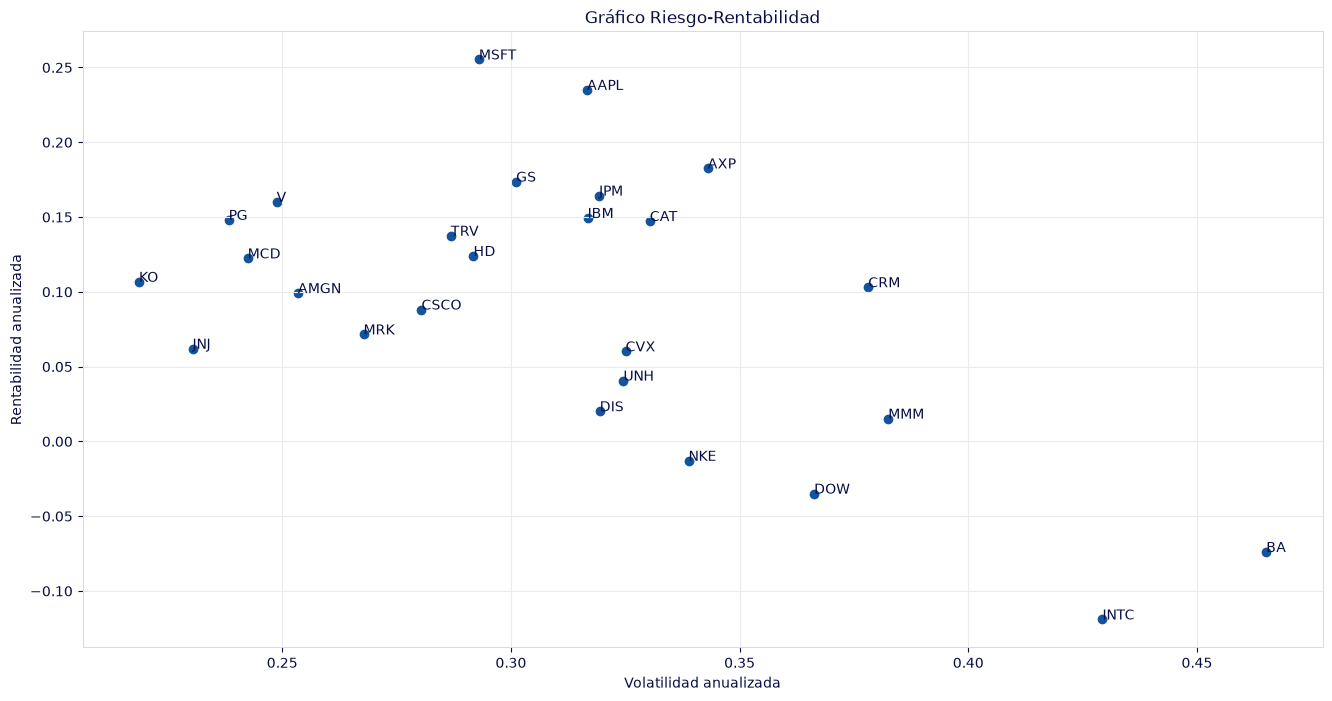

In [122]:
# Gráfico de riesgo-rentabilidad
fig, ax = plt.subplots(figsize=(16, 8))

ax.scatter(tabla_final["Volatilidad anualizada"], tabla_final["Rentabilidad anualizada"], color=paleta_bbva["azul_logotipo"])

for activo in tabla_final.index:
    ax.annotate(activo,(tabla_final.loc[activo, "Volatilidad anualizada"], tabla_final.loc[activo, "Rentabilidad anualizada"]), color=paleta_bbva["azul_profundo_texto"])

plt.xlabel("Volatilidad anualizada")
plt.ylabel("Rentabilidad anualizada")
plt.title("Gráfico Riesgo-Rentabilidad")
plt.savefig(os.path.join(ruta_graficos, ('Gráfico Riesgo-Rentabilidad' + '.png').replace(' ', '_')))
plt.show()

### Conclusiones: gráfico riesgo-rentabilidad

- En teoría financiera se espera una relación positiva entre riesgo y rentabilidad (a más riesgo, más rentabilidad exigida). Aquí, esa relación no se cumple en esta muestra: hay activos de alta volatilidad con rentabilidad baja o negativa, y activos de baja volatilidad con rentabilidad alta.
- Los activos más atractivos están en la zona superior izquierda (mucha rentabilidad con poca volatilidad): MSFT (27 % de rentabilidad anualizada con 29 % de volatilidad), y también PG, V, GS, JPM, AXP, IBM y MCD/KO. Son los activos que dominan en términos de media-varianza a los demás.
- Los activos de la zona inferior derecha son los menos eficientes, pues asumen más riesgo y obtienen menos: INTC, BA, DOW, MMM, NKE y DIS. Un inversor racional no debería elegirlos frente a alternativas con menos riesgo y más retorno, salvo que aporten diversificación.
- JNJ es el de menor volatilidad (25 %) pero también con una rentabilidad moderada (9 %): perfil claramente defensivo.
- AAPL queda aislado a la derecha (volatilidad 124 %) por el error de datos ya comentado; su posición real estaría mucho más a la izquierda, previsiblemente cerca de MSFT. No se puede extraer una conclusión fiable de este punto sin limpiar los datos.
- La rentabilidad pasada no garantiza la futura, y este resultado depende del periodo elegido (2018-2025, alcista y con sesgo a favor de tecnología y financieras).


## 13. COMPARACIÓN DE LOS RATIOS

Representamos los ratios de Sharpe y Sortino para poder comparar visualmente la relación entre rentabilidad y riesgo.


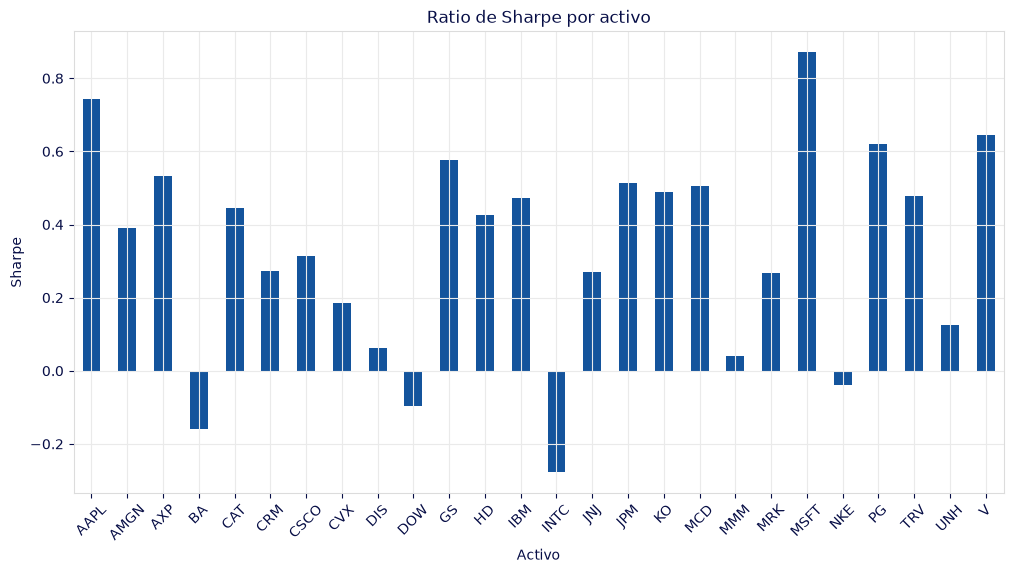

In [123]:
# Ratio de Sharpe
tabla_final["Sharpe"].plot(kind="bar", figsize=(12, 6), color=paleta_bbva["azul_logotipo"])

plt.title("Ratio de Sharpe por activo")
plt.xlabel("Activo")
plt.ylabel("Sharpe")
plt.xticks(rotation=45)
plt.savefig(os.path.join(ruta_graficos, ("Ratio de Sharpe por activo" + '.png').replace(' ', '_')))
plt.show()

### Conclusiones: ratio de Sharpe

- El Sharpe mide la rentabilidad obtenida por unidad de riesgo total (con r_f = 0 en este análisis). Cuanto más alto, mejor compensado está el riesgo asumido. MSFT lidera claramente (0,91), seguido de PG (0,72), V (0,67), GS (0,64), JPM (0,61), MCD (0,59), TRV, AXP, KO e IBM (en torno a 0,53-0,56). Son activos con rentabilidades altas y volatilidad moderada.
- INTC (-0,23) y BA (-0,15) tienen Sharpe negativo: han destruido valor asumiendo riesgo. NKE (0) ha rendido lo mismo que un activo sin riesgo (con r_f = 0), es decir, el riesgo no se ha visto compensado.
- Los valores con Sharpe entre 0 y 0,2 (DIS, DOW, MMM, UNH, AAPL) asumen riesgo con una compensación muy baja.
- El Sharpe de AAPL (0,19) está subestimado por la volatilidad inflada del dato erróneo; con datos limpios probablemente estaría entre los mejores.
- Como r_f = 0, los Sharpe están sobrestimados en términos absolutos (los tipos de interés no fueron cero en todo el periodo, sobre todo en 2022-2025), aunque el ranking relativo entre activos se mantendría.


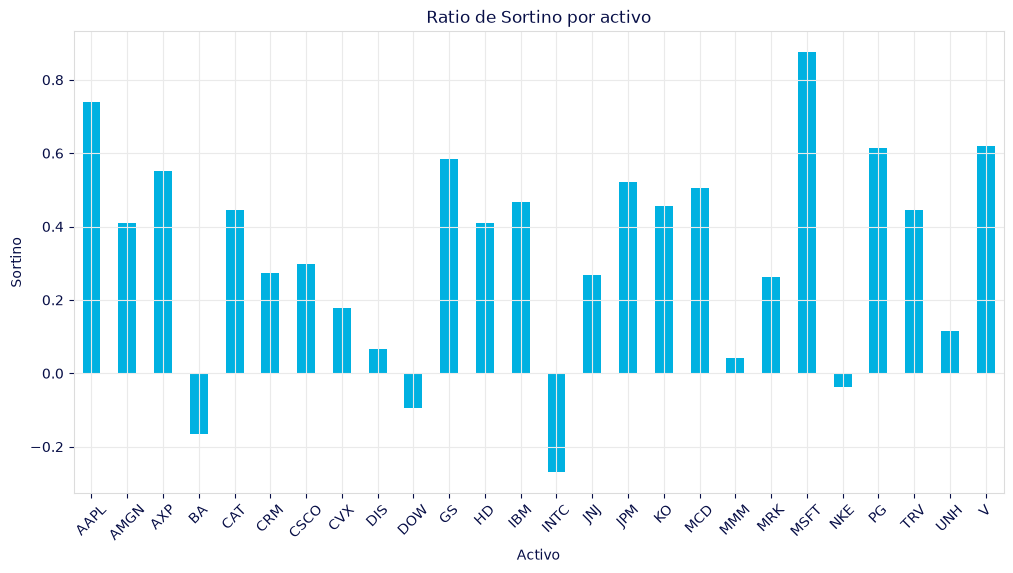

In [124]:
# Ratio de Sortino
tabla_final["Sortino"].plot(kind="bar", figsize=(12, 6), color=paleta_bbva["azul_celeste_aqua"])

plt.title("Ratio de Sortino por activo")
plt.xlabel("Activo")
plt.ylabel("Sortino")
plt.xticks(rotation=45)
plt.savefig(os.path.join(ruta_graficos, ("Ratio de Sortino por activo" + '.png').replace(' ', '_')))
plt.show()

### Conclusiones: ratio de Sortino

- El Sortino solo penaliza la volatilidad a la baja, que es la que realmente preocupa al inversor. Su perfil es muy parecido al del Sharpe: MSFT (0,92), PG (0,72), GS, JPM, MCD y V siguen a la cabeza e INTC y BA siguen en negativo. Esto da robustez al ranking.
- Donde ambos ratios difieren, hay información: si Sortino > Sharpe la distribución de rentabilidades es más favorable al alza (menos volatilidad "mala" que total), y si Sortino < Sharpe hay más riesgo a la baja relativo. Por ejemplo, TRV, V, KO y UNH tienen un Sortino algo menor que el Sharpe, lo que indica una mayor proporción de riesgo a la baja.
- AAPL pasa de 0,19 (Sharpe) a 0,45 (Sortino): el Sortino corrige en parte la distorsión del dato atípico, porque la subida del +300 % no cuenta como riesgo y solo penaliza la caída. Esto refuerza la conclusión de que el Sharpe de AAPL está subestimado.
- En general, los activos con mejor ratio son los de calidad (beneficios estables, posición dominante en su sector), y los peores (INTC, BA, NKE) son empresas con problemas idiosincráticos (crisis de producto, pérdida de cuota o de competitividad).


## 14. MATRIZ DE CORRELACIONES

Como análisis adicional, representamos la matriz de correlaciones de las rentabilidades de los activos.


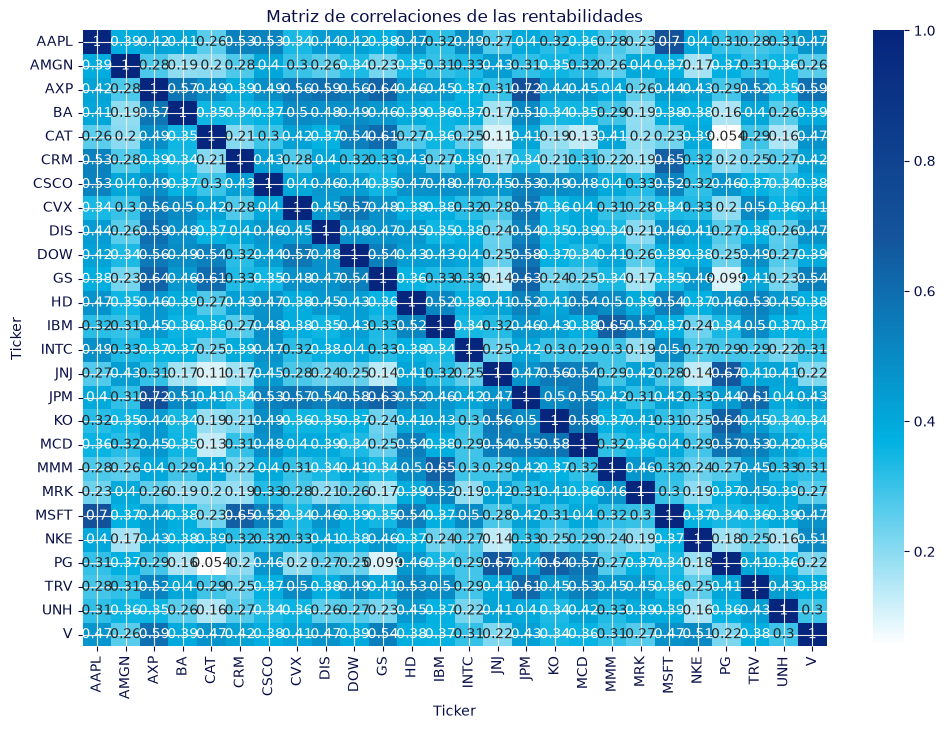

In [125]:
# Matriz de correlaciones de las rentabilidades
correlation_mat = rentabilidades.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(correlation_mat, annot=True, cmap=cmap_bbva)
plt.title("Matriz de correlaciones de las rentabilidades")
plt.savefig(os.path.join(ruta_graficos, ("Matriz de correlaciones de las rentabilidades" + '.png').replace(' ', '_')))
plt.show()

### Conclusiones: matriz de correlaciones

- Las correlaciones son positivas (salvo valores 0 ligados a AAPL) y en su mayoría moderadas (0,3-0,6). Esto refleja el factor de mercado común: los activos tienden a moverse en la misma dirección, sobre todo en crisis.
- Las correlaciones más altas aparecen dentro de sectores o con exposición económica similar: JPM-AXP (0,76), CVX-DOW (0,70) (energía y materias primas), JNJ-KO (~0,71), KO-PG (0,69) y JNJ-AMGN (0,68) (defensivas y salud/consumo básico), y MSFT-CRM (0,65) (tecnología). Comparten riesgos comunes, por lo que combinarlos aporta poca diversificación.
- Las correlaciones más bajas indican mayor potencial de diversificación; por ejemplo: NKE, UNH y GS frente a varios activos defensivos o industriales muestran valores cercanos a 0,1-0,3.
- AAPL presenta correlaciones anormalmente bajas con casi todos los activos (cercanas a 0), lo que tampoco es razonable para un gigante tecnológico del índice: es de nuevo consecuencia del dato atípico, que distorsiona la covarianza. Hasta limpiar la serie no se puede usar AAPL como activo diversificador con garantías.
- Como ninguna correlación es cercana a 1 ni claramente negativa, diversificar reduce el riesgo específico, pero no el riesgo sistemático: una cartera de estos 26 activos seguirá cayendo en una crisis general, aunque menos que un activo individual.


## 15. CONCLUSIONES GENERALES

1. El periodo 2018-2025 fue alcista, pero con un shock común muy claro en marzo de 2020. Los movimientos de mercado explican buena parte del comportamiento de cada activo (riesgo sistemático).
2. Rentabilidad y riesgo no fueron de la mano: los activos más eficientes (mayor Sharpe/Sortino) fueron MSFT, PG, V, GS, JPM y MCD; los menos eficientes, INTC, BA, NKE, DIS, DOW y MMM. Para valorar un activo no basta con mirar la rentabilidad, hay que medirla en relación al riesgo.
3. El riesgo no es constante: la volatilidad se agrupa en el tiempo y se dispara en las crisis, y el drawdown ofrece una visión del riesgo más cercana a la experiencia del inversor que la desviación típica.
4. Los sectores defensivos (consumo básico y salud: PG, JNJ, KO, MCD) ofrecen menor volatilidad y menores caídas máximas; los cíclicos o con problemas propios (BA, INTC, DOW) sufren más drawdown y peor rentabilidad ajustada al riesgo.
5. Diversificación: las correlaciones son positivas y moderadas, así que combinar activos de sectores distintos reduce el riesgo específico, pero no elimina el riesgo de mercado.
6. Calidad de datos: la serie de AAPL contiene un dato atípico en 2020 (rentabilidad +300 % y luego -75 %) que distorsiona su volatilidad, su drawdown, su Sharpe y sus correlaciones. Antes de extraer conclusiones sobre AAPL (y de tomar decisiones de inversión) habría que revisar y limpiar los datos (splits, ajustes, valores erróneos). Lo mismo aplica a otros picos puntuales (por ejemplo: CAT, MMM, DIS).
7. Limitaciones del análisis: se usa r_f = 0 (sobrestima los ratios en valor absoluto), un único periodo histórico, y la rentabilidad pasada no garantiza la futura.


## 16. ANÁLISIS DE VARIABLES CUALITATIVAS (YFINANCE)

Hasta aquí el análisis ha sido puramente cuantitativo (precios, rentabilidades y riesgo). En esta sección se añaden variables **cualitativas** de cada activo disponibles en la librería `yfinance`, para contextualizar los números:

- **Perfil del activo:** sector, industria, país, consenso de analistas y riesgo de gobierno corporativo.
- **Holders principales:** reparto del capital entre *insiders* (directivos y consejeros) e instituciones.
- **Holders institucionales:** quiénes son los mayores accionistas y cuánto capital concentran.
- **Splits:** desdoblamientos de acciones, que explican saltos bruscos en precios no ajustados.
- **Dividendos:** pagos a los accionistas, rentabilidad por dividendo y evolución en el tiempo.

In [126]:
# Librería yfinance (si no está instalada: pip install yfinance)
import yfinance as yf
from IPython.display import display

tickers = list(datos.columns)
activos_yf = {t: yf.Ticker(t) for t in tickers}

# Rango temporal del dataset (sin zona horaria, para poder cruzarlo con los datos de yfinance)
indice_precios = pd.DatetimeIndex(datos.index)
if indice_precios.tz is not None:
    indice_precios = indice_precios.tz_localize(None)
inicio_periodo, fin_periodo = indice_precios.min(), indice_precios.max()

# Rentabilidades diarias con el mismo índice sin zona horaria
rent_sin_tz = rentabilidades.copy()
rent_sin_tz.index = indice_precios

def sin_zona_horaria(serie):
    """Quita la zona horaria del índice (yfinance la devuelve) para poder cruzar con `datos`."""
    serie = serie.copy()
    if getattr(serie.index, "tz", None) is not None:
        serie.index = serie.index.tz_localize(None)
    return serie

def obtener(activo, atributo):
    """Descarga un atributo de yfinance sin que un fallo en un activo pare el notebook."""
    try:
        return getattr(activos_yf[activo], atributo)
    except Exception as e:
        print(f"[aviso] {activo}: no se pudo obtener '{atributo}' ({type(e).__name__})")
        return None

### 16.1 Perfil cualitativo de los activos

Sector, industria, país, tamaño, beta, consenso de analistas y riesgo de gobierno corporativo (puntuación de 1 a 10, donde 1 es el menor riesgo). Sirve para ver de un vistazo qué tipo de empresa hay detrás de cada serie de precios.

In [127]:
# Información general de cada activo (foto actual)
campos_perfil = {
    "longName": "Nombre",
    "sector": "Sector",
    "industry": "Industria",
    "country": "País",
    "marketCap": "Capitalización ($)",
    "beta": "Beta",
    "recommendationKey": "Recomendación analistas",
    "numberOfAnalystOpinions": "Nº analistas",
    "overallRisk": "Riesgo gobierno corporativo (1-10)",}

info = {}
for t in tickers:
    d = obtener(t, "info")
    info[t] = d if isinstance(d, dict) else {}

perfil = pd.DataFrame(
    {t: {nombre: info[t].get(campo) for campo, nombre in campos_perfil.items()} for t in tickers}).T
perfil.index.name = "Activo"
perfil

,Nombre,Sector,Industria,País,Capitalización ($),Beta,Recomendación analistas,Nº analistas,Riesgo gobierno corporativo (1-10)
Activo,,,,,,,,,
AAPL,Apple Inc.,Technology,Consumer Electronics,United States,5132548833280,1.089,buy,38,None
AMGN,Amgen Inc.,Healthcare,Drug Manufacturers - General,United States,258113929216,0.417,hold,29,None
AXP,American Express Company,Financial Services,Credit Services,United States,223025594368,1.077,buy,24,None
BA,The Boeing Company,Industrials,Aerospace & Defense,United States,140802490368,1.331,strong_buy,26,None
CAT,Caterpillar Inc.,Industrials,Farm & Heavy Construction Machinery,United States,269292486656,1.64,buy,26,None
CRM,"Salesforce, Inc.",Technology,Software - Application,United States,186442416128,1.233,buy,53,None
CSCO,"Cisco Systems, Inc.",Technology,Communication Equipment,United States,405869592576,1.002,buy,25,None
CVX,Chevron Corporation,Energy,Oil & Gas Integrated,United States,421689917440,0.453,buy,24,None
DIS,The Walt Disney Company,Communication Services,Entertainment,United States,206718959616,1.426,strong_buy,32,None


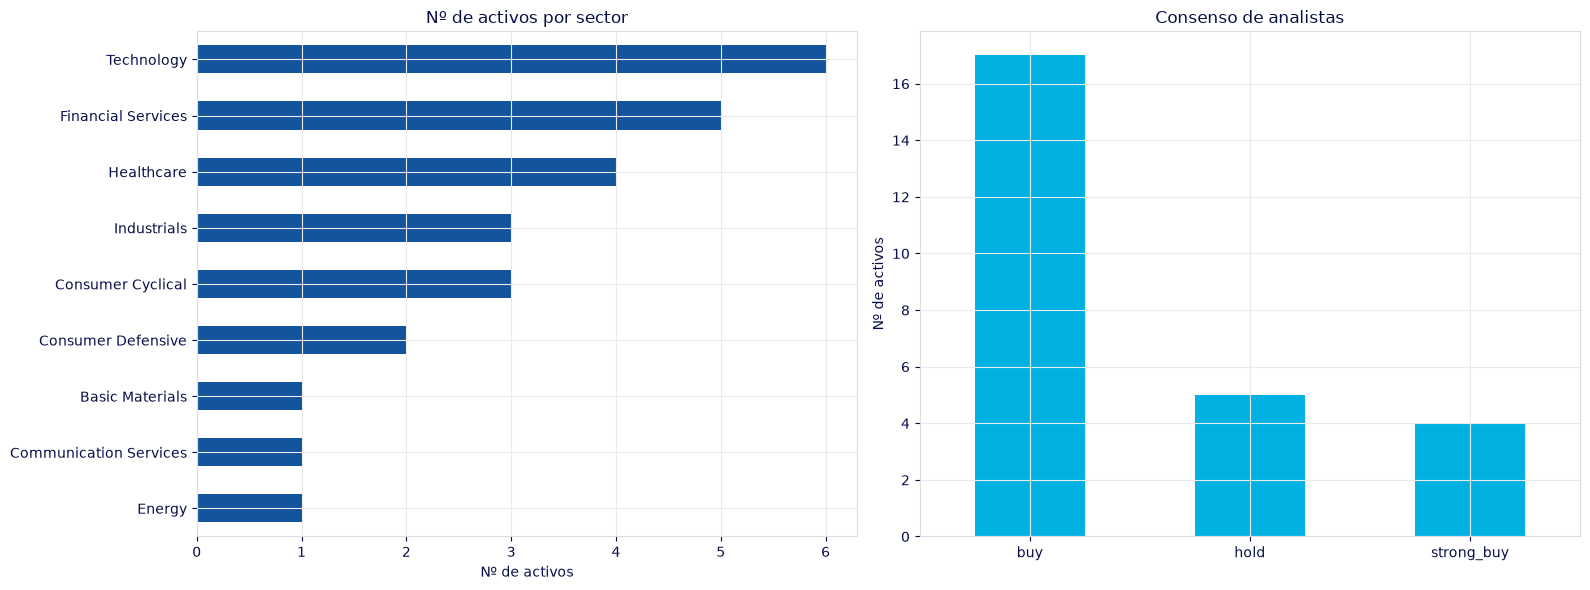

In [128]:
# Representación del perfil: composición por sector y consenso de analistas
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sectores = perfil["Sector"].value_counts()
if len(sectores) > 0:
    sectores.sort_values().plot(kind="barh", ax=axes[0], color=paleta_bbva["azul_logotipo"])
axes[0].set_title("Nº de activos por sector")
axes[0].set_xlabel("Nº de activos")
axes[0].set_ylabel("")

recomendaciones = perfil["Recomendación analistas"].value_counts()
if len(recomendaciones) > 0:
    recomendaciones.plot(kind="bar", ax=axes[1], color=paleta_bbva["azul_celeste_aqua"])
axes[1].set_title("Consenso de analistas")
axes[1].set_xlabel("")
axes[1].set_ylabel("Nº de activos")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig(os.path.join(ruta_graficos, ("N_activos por sector" + '.png').replace(' ', '_')))
plt.show()

### 16.2 Holders principales: insiders e instituciones

Porcentaje del capital en manos de **insiders** (directivos y consejeros) y de **instituciones** (fondos, gestoras, aseguradoras...). Muchos insiders suelen indicar alineación de intereses con el accionista; mucha presencia institucional indica un valor muy seguido por el "dinero profesional". Los porcentajes pueden sumar más de 100 % porque una misma acción puede computarse en varias instituciones.

In [129]:
# Holders principales (insiders e instituciones)
filas = {}
for t in tickers:
    mh = obtener(t, "major_holders")
    fila = mh["Value"].to_dict() if isinstance(mh, pd.DataFrame) and "Value" in mh.columns else {}
    filas[t] = {"Insiders (%)": fila.get("insidersPercentHeld", info[t].get("heldPercentInsiders")),
        "Instituciones (%)": fila.get("institutionsPercentHeld", info[t].get("heldPercentInstitutions")),
        "Instituciones s/ free float (%)": fila.get("institutionsFloatPercentHeld"),
        "Nº instituciones": fila.get("institutionsCount"),}

tabla_holders = pd.DataFrame.from_dict(
    filas, orient="index",
    columns=["Insiders (%)", "Instituciones (%)", "Instituciones s/ free float (%)", "Nº instituciones"]).apply(pd.to_numeric, errors="coerce")
tabla_holders.index.name = "Activo"

tabla_holders.style.format({
    "Insiders (%)": "{:.2%}",
    "Instituciones (%)": "{:.2%}",
    "Instituciones s/ free float (%)": "{:.2%}",
    "Nº instituciones": "{:,.0f}",}, na_rep="-")

,Insiders (%),Instituciones (%),Instituciones s/ free float (%),Nº instituciones
Activo,,,,
AAPL,1.65%,66.57%,67.69%,"7,735"
AMGN,0.23%,85.14%,85.34%,"4,086"
AXP,22.72%,65.14%,84.29%,"3,728"
BA,0.06%,76.70%,76.75%,"3,109"
CAT,0.22%,73.33%,73.50%,"4,843"
CRM,2.98%,87.14%,89.81%,"3,608"
CSCO,0.05%,83.24%,83.29%,"5,121"
CVX,4.83%,72.06%,75.72%,"5,085"
DIS,0.07%,78.83%,78.88%,"3,864"


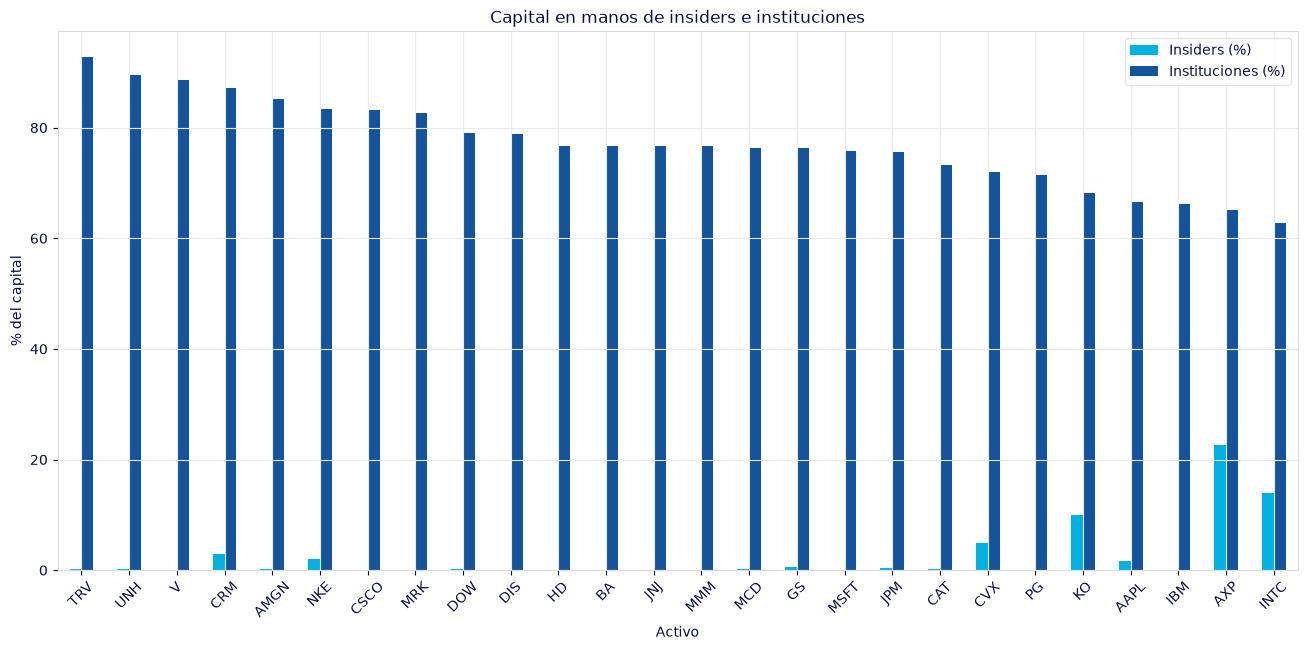

In [130]:
# Insiders vs instituciones por activo
plot_holders = (tabla_holders[["Insiders (%)", "Instituciones (%)"]] * 100).dropna(how="all")

if plot_holders.empty:
    print("No hay datos de holders principales para representar.")
else:
    plot_holders = plot_holders.sort_values("Instituciones (%)", ascending=False)
    plot_holders.plot(kind="bar", figsize=(16, 7), color=[paleta_bbva["azul_celeste_aqua"], paleta_bbva["azul_logotipo"]])
    plt.title("Capital en manos de insiders e instituciones")
    plt.xlabel("Activo")
    plt.ylabel("% del capital")
    plt.xticks(rotation=45)
    plt.legend()
    plt.savefig(os.path.join(ruta_graficos, ("Capital en manos de insiders e instituciones" + '.png').replace(' ', '_')))
    plt.show()

### 16.3 Holders institucionales

Quiénes son los mayores accionistas institucionales de cada activo, cuánto concentran los 5 y los 10 primeros, y qué gestoras se repiten en muchos activos. Que unas pocas gestoras sean accionistas de casi todos los valores es una fuente de riesgo común que no aparece en los precios, pero que ayuda a entender por qué las correlaciones son positivas.

In [131]:
# Holders institucionales de cada activo
holders_inst = {t: obtener(t, "institutional_holders") for t in tickers}

def columna_pct(df):
    """Nombre de la columna con el % del capital (cambia según la versión de yfinance)."""
    return next((c for c in ["pctHeld", "% Out"] if c in df.columns), None)

filas = {}
for t, df in holders_inst.items():
    if not isinstance(df, pd.DataFrame) or df.empty or columna_pct(df) is None or "Holder" not in df.columns:
        continue
    col = columna_pct(df)
    df = df.sort_values(col, ascending=False)
    filas[t] = {"Mayor holder": df.iloc[0]["Holder"],
        "% mayor holder": df.iloc[0][col],
        "% top 5": df[col].head(5).sum(),
        "% top 10": df[col].head(10).sum()}

tabla_inst = pd.DataFrame.from_dict(
    filas, orient="index",
    columns=["Mayor holder", "% mayor holder", "% top 5", "% top 10"])
tabla_inst.index.name = "Activo"

if tabla_inst.empty:
    print("No se han obtenido holders institucionales.")
else:
    for c in ["% mayor holder", "% top 5", "% top 10"]:
        tabla_inst[c] = pd.to_numeric(tabla_inst[c], errors="coerce")
    display(tabla_inst.style.format({
        "% mayor holder": "{:.2%}", "% top 5": "{:.2%}", "% top 10": "{:.2%}"}, na_rep="-"))

,Mayor holder,% mayor holder,% top 5,% top 10
Activo,,,,
AAPL,Blackrock Inc.,7.97%,23.58%,31.91%
AMGN,Blackrock Inc.,9.13%,29.70%,42.00%
AXP,"Berkshire Hathaway, Inc",22.61%,41.51%,49.46%
BA,Blackrock Inc.,7.70%,30.30%,41.02%
CAT,Blackrock Inc.,8.26%,28.06%,37.25%
CRM,Blackrock Inc.,8.84%,25.86%,34.30%
CSCO,Blackrock Inc.,9.10%,26.84%,36.46%
CVX,Blackrock Inc.,7.84%,28.09%,36.51%
DIS,Blackrock Inc.,7.93%,26.12%,34.74%


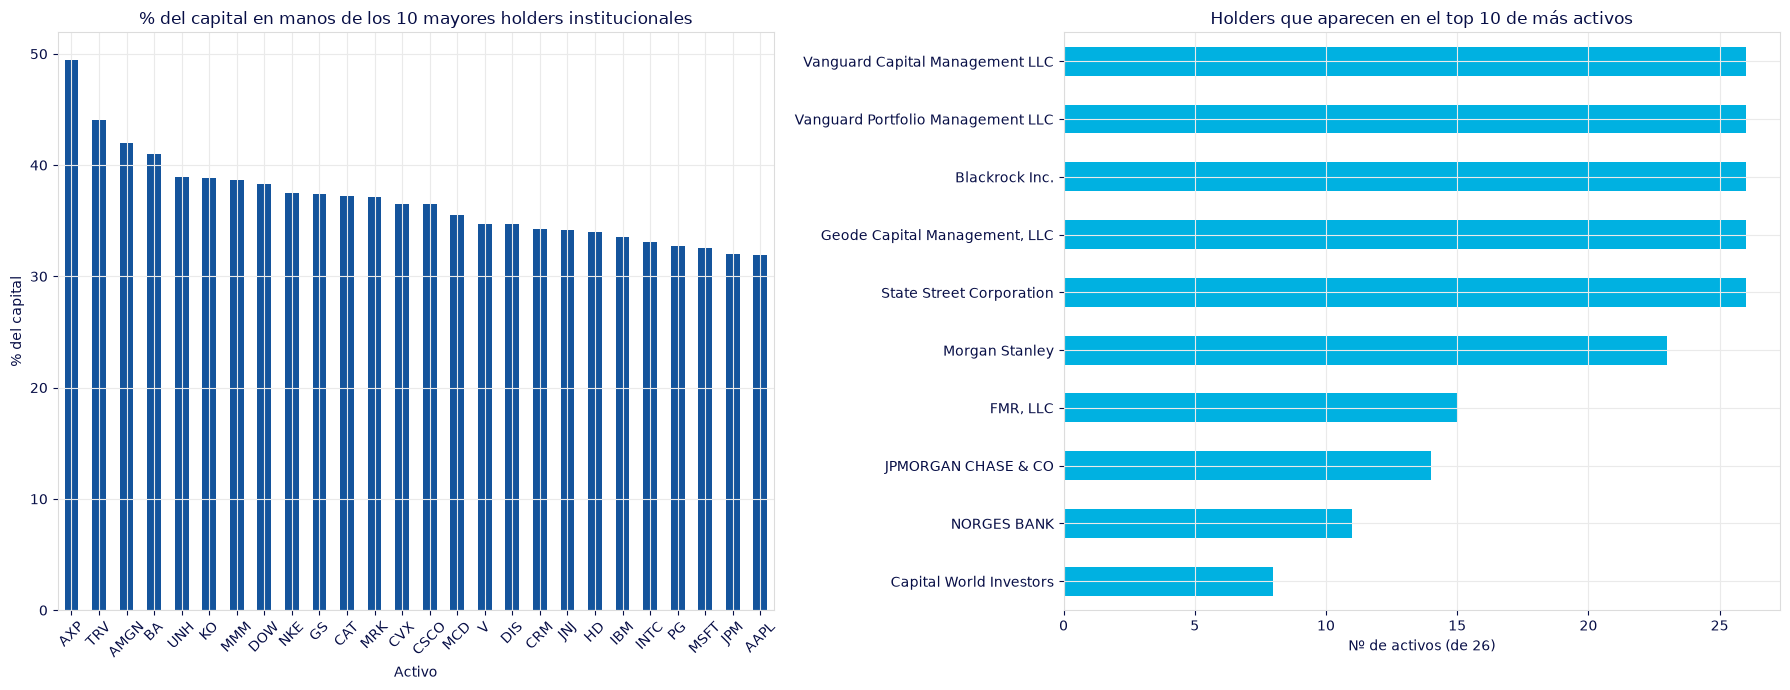

In [132]:
# Concentración institucional (top 10) y gestoras que más se repiten entre los activos
if not tabla_inst.empty:
    frecuencia = {}
    for t, df in holders_inst.items():
        if not isinstance(df, pd.DataFrame) or df.empty or columna_pct(df) is None or "Holder" not in df.columns:
            continue
        for h in df.sort_values(columna_pct(df), ascending=False).head(10)["Holder"]:
            frecuencia[h] = frecuencia.get(h, 0) + 1
    frecuencia = pd.Series(frecuencia, dtype=float).sort_values(ascending=False)

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))

    (tabla_inst["% top 10"].dropna().sort_values(ascending=False) * 100).plot(
        kind="bar", ax=axes[0], color=paleta_bbva["azul_logotipo"])
    axes[0].set_title("% del capital en manos de los 10 mayores holders institucionales")
    axes[0].set_xlabel("Activo")
    axes[0].set_ylabel("% del capital")
    axes[0].tick_params(axis="x", rotation=45)

    if len(frecuencia) > 0:
        frecuencia.head(10).sort_values().plot(kind="barh", ax=axes[1], color=paleta_bbva["azul_celeste_aqua"])
    axes[1].set_title("Holders que aparecen en el top 10 de más activos")
    axes[1].set_xlabel(f"Nº de activos (de {len(tabla_inst)})")
    axes[1].set_ylabel("")

    plt.tight_layout()
    plt.savefig(os.path.join(ruta_graficos, ("% del capital en manos de los 10 mayores holders institucionales" + '.png').replace(' ', '_')))
    plt.show()

## DETALLE DE HOLDERS INSTITUCIONALES DE ACTIVOS QUE HEMOS ELEGIDO

## COCA-COLA

,Date Reported,Holder,pctHeld,Shares,Value,pctChange
0,2026-06-30,Blackrock Inc.,0.0797,1162996939,410747250397,0.0160
1,2026-06-30,Vanguard Capital Management LLC,0.0657,959107911,338737724982,0.0055
2,2026-06-30,State Street Corporation,0.0421,615129929,217251583818,0.0212
3,2026-06-30,"Geode Capital Management, LLC",0.0254,371336543,131148637536,0.0074
4,2026-06-30,Vanguard Portfolio Management LLC,0.0229,334119156,118004201068,0.0081
5,2026-06-30,"FMR, LLC",0.0223,325348754,114906670554,0.0582
6,2026-06-30,Morgan Stanley,0.0166,242614238,85686494799,-0.0076
7,2026-06-30,JPMORGAN CHASE & CO,0.0157,228762008,80794164309,-0.0123
8,2026-06-30,"Berkshire Hathaway, Inc",0.0156,227917808,80496009760,0.0000
9,2026-06-30,NORGES BANK,0.0131,190726866,67360913136,-0.0079


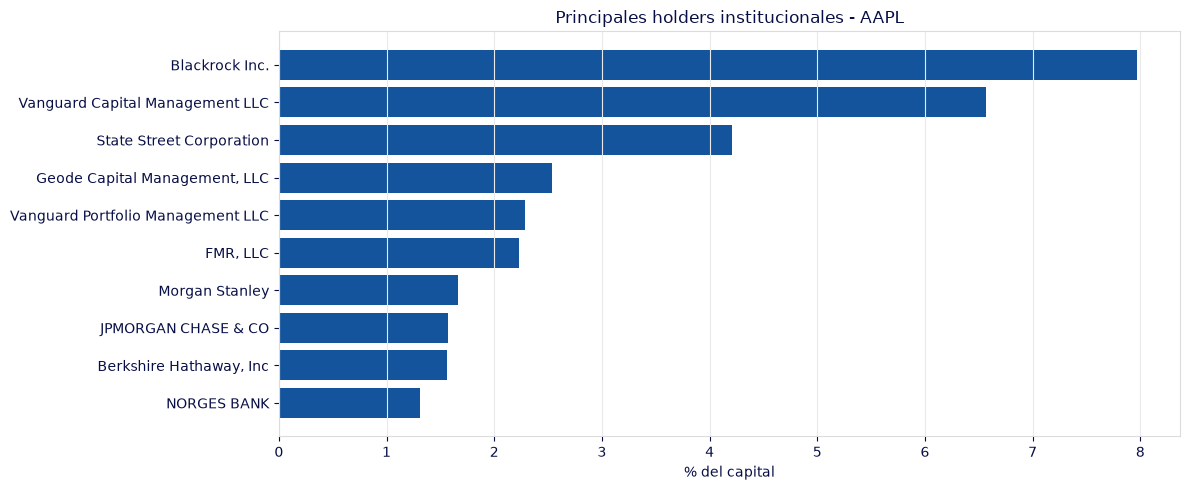

In [133]:
# Detalle de los holders institucionales de CAO
activo_ejemplo = "CAO" if "CAO" in tickers else tickers[0]
def ver_holders_institucionales(activo, top=10):
    df = holders_inst.get(activo)
    if not isinstance(df, pd.DataFrame) or df.empty or columna_pct(df) is None or "Holder" not in df.columns:
        print(f"No hay holders institucionales disponibles para {activo}.")
        return
    col = columna_pct(df)
    df = df.sort_values(col, ascending=False).head(top)
    display(df)

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.barh(df["Holder"].astype(str)[::-1], df[col][::-1] * 100, color=paleta_bbva["azul_logotipo"])
    ax.set_title(f"Principales holders institucionales - {activo}")
    ax.set_xlabel("% del capital")
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.savefig(os.path.join(ruta_graficos, (f'Principales holders institucionales - {activo}' + '.png').replace(' ', '_')))
    plt.show()

ver_holders_institucionales(activo_ejemplo)

## GOLDMAN SACHS

,Date Reported,Holder,pctHeld,Shares,Value,pctChange
0,2026-06-30,Blackrock Inc.,0.0829,23900376,22110237254,-0.0037
1,2026-06-30,State Street Corporation,0.0653,18830464,17420061786,-0.0221
2,2026-06-30,Vanguard Capital Management LLC,0.0639,18425670,17045586867,0.0021
3,2026-06-30,JPMORGAN CHASE & CO,0.0279,8039070,7436943460,0.1141
4,2026-06-30,Vanguard Portfolio Management LLC,0.0250,7215421,6674985790,0.0010
5,2026-06-30,Morgan Stanley,0.0244,7030974,6504353875,0.0314
6,2026-06-30,"Fisher Asset Management, LLC",0.0241,6964113,6442500766,0.0200
7,2026-06-30,"Geode Capital Management, LLC",0.0241,6948585,6428135813,-0.0234
8,2026-06-30,Bank of America Corporation,0.0232,6680811,6180418092,0.0350
9,2026-06-30,"FMR, LLC",0.0134,3866640,3577028569,0.1572


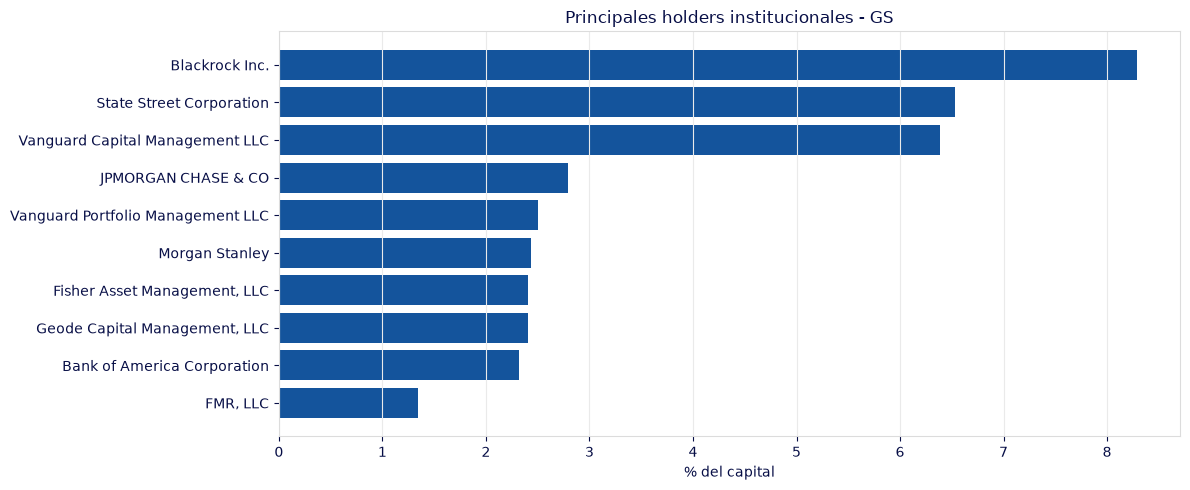

In [134]:
# Detalle de los holders institucionales de GS
activo_ejemplo = "GS" if "GS" in tickers else tickers[0]
def ver_holders_institucionales(activo, top=10):
    df = holders_inst.get(activo)
    if not isinstance(df, pd.DataFrame) or df.empty or columna_pct(df) is None or "Holder" not in df.columns:
        print(f"No hay holders institucionales disponibles para {activo}.")
        return
    col = columna_pct(df)
    df = df.sort_values(col, ascending=False).head(top)
    display(df)

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.barh(df["Holder"].astype(str)[::-1], df[col][::-1] * 100, color=paleta_bbva["azul_logotipo"])
    ax.set_title(f"Principales holders institucionales - {activo}")
    ax.set_xlabel("% del capital")
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.savefig(os.path.join(ruta_graficos, (f"Principales holders institucionales - {activo}" + '.png').replace(' ', '_')))
    plt.show()

ver_holders_institucionales(activo_ejemplo)

## CATERPILLAR

,Date Reported,Holder,pctHeld,Shares,Value,pctChange
0,2026-06-30,Blackrock Inc.,0.0826,37991505,22256659094,0.0221
1,2026-06-30,State Street Corporation,0.0748,34392316,20148137134,-0.0140
2,2026-06-30,Vanguard Capital Management LLC,0.0654,30077764,17620532265,-0.0052
3,2026-06-30,State Farm Mutual Automobile Insurance Co,0.0316,14509304,8500022118,-0.0038
4,2026-06-30,Vanguard Portfolio Management LLC,0.0262,12026244,7045364823,0.0274
5,2026-06-30,"Geode Capital Management, LLC",0.0243,11175493,6546967221,0.0043
6,2026-06-30,"Fisher Asset Management, LLC",0.0216,9942521,5824652127,0.0170
7,2026-06-30,Morgan Stanley,0.0163,7504426,4396336791,0.0006
8,2026-06-30,JPMORGAN CHASE & CO,0.0159,7325731,4291651449,1.4913
9,2026-06-30,Gates Foundation Trust,0.0138,6353614,3722153697,0.0000


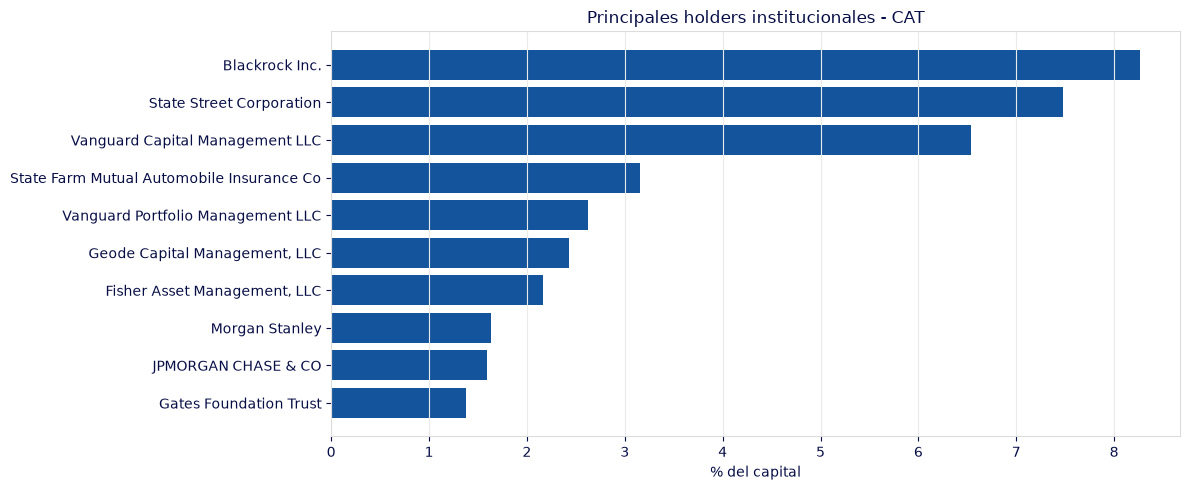

In [135]:
# Detalle de los holders institucionales de CAT
activo_ejemplo = "CAT" if "CAT" in tickers else tickers[0]
def ver_holders_institucionales(activo, top=10):
    df = holders_inst.get(activo)
    if not isinstance(df, pd.DataFrame) or df.empty or columna_pct(df) is None or "Holder" not in df.columns:
        print(f"No hay holders institucionales disponibles para {activo}.")
        return
    col = columna_pct(df)
    df = df.sort_values(col, ascending=False).head(top)
    display(df)

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.barh(df["Holder"].astype(str)[::-1], df[col][::-1] * 100, color=paleta_bbva["azul_logotipo"])
    ax.set_title(f"Principales holders institucionales - {activo}")
    ax.set_xlabel("% del capital")
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.savefig(os.path.join(ruta_graficos, (f"Principales holders institucionales - {activo}" + '.png').replace(' ', '_')))
    plt.show()

ver_holders_institucionales(activo_ejemplo)

### 16.4 Splits

Un *split* multiplica el número de acciones y divide el precio (un split 4:1 divide el precio entre 4). Si la serie de precios no está bien ajustada, el split aparece como un salto brusco que **parece** una rentabilidad extrema, pero no lo es. Por eso se cruzan los splits con las rentabilidades diarias del dataset: así se puede comprobar si los datos atípicos comentados en las conclusiones de las secciones anteriores coinciden con un evento corporativo.

In [136]:
#splits de los activos
splits = {}
for t in tickers:
    s = obtener(t, "splits")
    
    if isinstance(s, pd.Series) and len(s) > 0:
        s = sin_zona_horaria(s)
        splits[t] = s

#1.TABLA RESUMEN: TODOS LOS ACTIVOS
resumen_splits = []

for t in tickers:   
    s = splits.get(t, pd.Series(dtype=float))
    
    #solo splits dentro del periodo analizado
    if len(s) > 0:
        s_periodo = s[(s.index >= inicio_periodo) & (s.index <= fin_periodo)]
    else:
        s_periodo = s   
    if len(s_periodo) > 0:  
        resumen_splits.append({"Activo": t,
            "Nº splits en periodo": len(s_periodo),
            "Fechas": ", ".join(
                fecha.strftime("%Y-%m-%d")
                for fecha in s_periodo.index),
            "Ratios": ", ".join(
                f"{ratio:g}:1"
                for ratio in s_periodo.values),
            "Tiene split": "Sí"})       
    else:        
        resumen_splits.append({"Activo": t,
            "Nº splits en periodo": 0,
            "Fechas": "-",
            "Ratios": "-", "Tiene split": "No"})

tabla_resumen_splits = pd.DataFrame(resumen_splits)
tabla_resumen_splits = tabla_resumen_splits.sort_values(["Tiene split", "Activo"], ascending=[False, True]).reset_index(drop=True)

display(tabla_resumen_splits)

#tabla de los splits existentes
filas_splits = []
for t, s in splits.items():   
    s_periodo = s[(s.index >= inicio_periodo) & (s.index <= fin_periodo)]
    for fecha, ratio in s_periodo.items():        
        tipo = "Split directo" if ratio > 1 else "Contrasplit"        
        filas_splits.append({"Activo": t, "Fecha": fecha, "Ratio": ratio, "Tipo": tipo})
tabla_splits = pd.DataFrame(filas_splits, columns=["Activo", "Fecha", "Ratio", "Tipo"])

if not tabla_splits.empty: 
    tabla_splits = tabla_splits.sort_values("Fecha").reset_index(drop=True)   
    display(tabla_splits.style.format({"Fecha": "{:%Y-%m-%d}", "Ratio": "{:g}:1"}))   
else:
    print("No se han encontrado splits dentro del periodo analizado.")

,Activo,Nº splits en periodo,Fechas,Ratios,Tiene split
0,AAPL,1,2020-08-31,4:1,Sí
1,IBM,1,2021-11-04,1.046:1,Sí
2,MMM,1,2024-04-01,1.196:1,Sí
3,MRK,1,2021-06-03,1.048:1,Sí
4,AMGN,0,-,-,No
5,AXP,0,-,-,No
6,BA,0,-,-,No
7,CAT,0,-,-,No
8,CRM,0,-,-,No
9,CSCO,0,-,-,No


,Activo,Fecha,Ratio,Tipo
0,AAPL,2020-08-31,4:1,Split directo
1,MRK,2021-06-03,1.048:1,Split directo
2,IBM,2021-11-04,1.046:1,Split directo
3,MMM,2024-04-01,1.196:1,Split directo


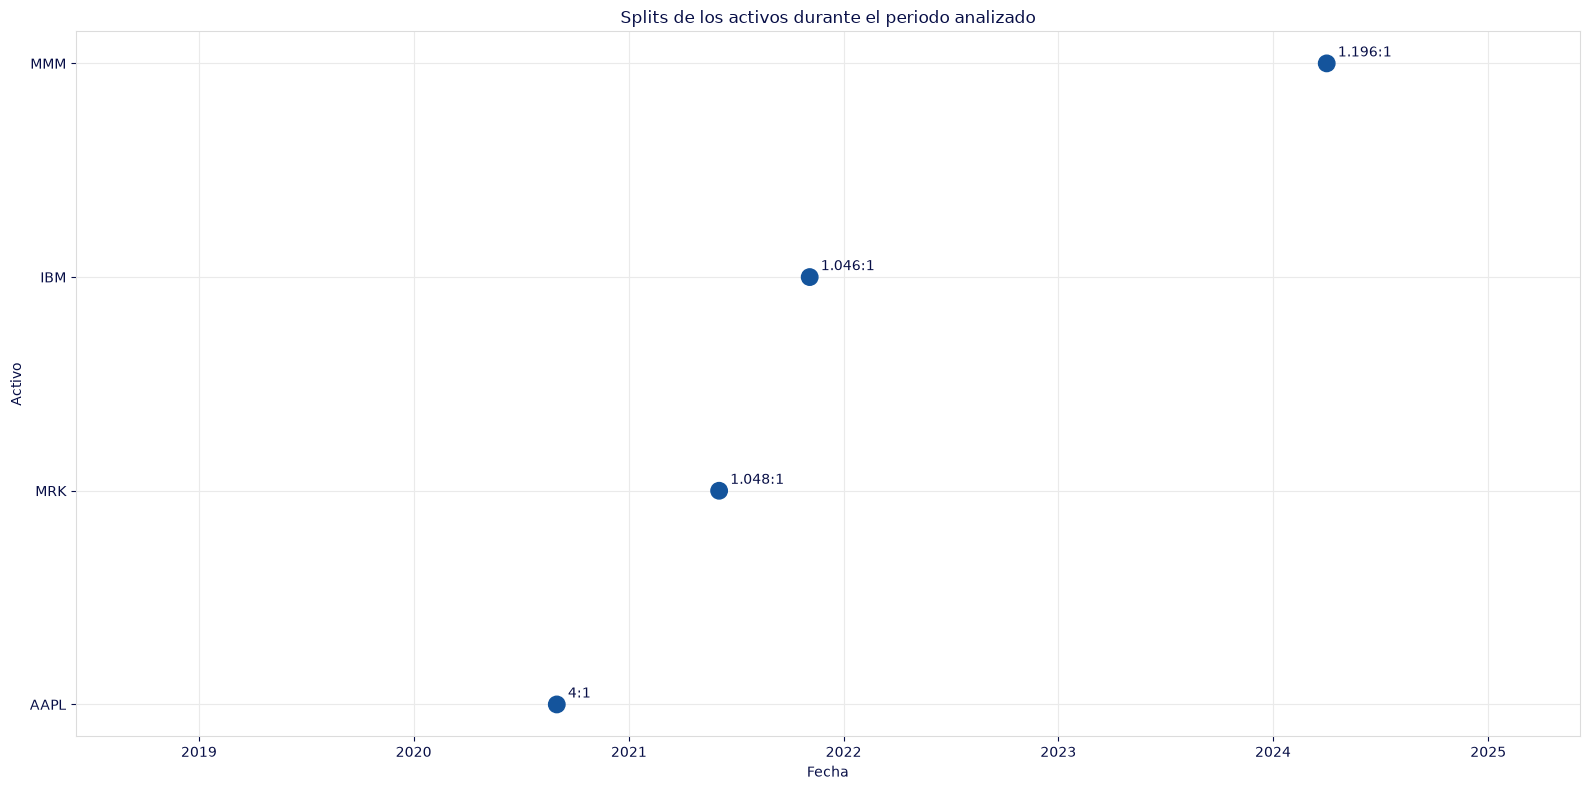

In [137]:
#Graficos de splits
if tabla_splits.empty:
    print("No hay splits que representar.")
else:   
    fig, ax = plt.subplots(figsize=(16, 8))   
    colores = [
        paleta_bbva["azul_logotipo"]
        if tipo == "Split directo"
        else paleta_bbva["naranja_alerta"]
        for tipo in tabla_splits["Tipo"]]
    
    ax.scatter(tabla_splits["Fecha"], tabla_splits["Activo"], s=140, c=colores, zorder=3)
    
    #ponemos el ratio al lado de cada punto
    for _, fila in tabla_splits.iterrows():        
        ax.annotate(f"{fila['Ratio']:g}:1", (fila["Fecha"], fila["Activo"]), textcoords="offset points", xytext=(8, 5))
    
    ax.set_xlim(inicio_periodo, fin_periodo)
    ax.set_title("Splits de los activos durante el periodo analizado")
    ax.set_xlabel("Fecha")
    ax.set_ylabel("Activo")
    
    plt.tight_layout()
    plt.savefig(os.path.join(ruta_graficos, ('Splits de los activos durante el periodo analizado' + '.png').replace(' ', '_')))
    plt.show()

In [138]:
#CRUCE ENTRE SPLITS Y RENTABILIDADES EXTREMAS
umbral_salto = 0.25
ventana_dias = 5

filas_saltos = []
for t in rent_sin_tz.columns:
    r = rent_sin_tz[t].dropna()
    
    # movimientos superiores al 25%
    movimientos_extremos = r[r.abs() > umbral_salto]   
    for fecha, valor in movimientos_extremos.items():
        
        split_cercano = "No"
        ratio_split = np.nan
        fecha_split = pd.NaT       
        if t in splits:            
            s = splits[t]           
            #splits a máximo 5 días de distancia
            cercanos = s[np.abs((s.index - fecha) / pd.Timedelta(days=1)) <= ventana_dias]
            
            if len(cercanos) > 0:                
                fecha_split = cercanos.index[0]
                ratio_split = cercanos.iloc[0]                
                split_cercano = "Sí"
        
        filas_saltos.append({"Activo": t, "Fecha": fecha, "Rentabilidad diaria": valor, "Split cercano": split_cercano, "Fecha split": fecha_split, "Ratio split": ratio_split})
tabla_saltos = pd.DataFrame(filas_saltos)

if tabla_saltos.empty:   
    print(f"No hay rentabilidades diarias superiores al "
        f"{umbral_salto:.0%} en valor absoluto.")    
else:   
    display(
        tabla_saltos.sort_values(["Activo", "Fecha"]).style.format({
            "Fecha": "{:%Y-%m-%d}",
            "Rentabilidad diaria": "{:.2%}",
            "Fecha split": "{:%Y-%m-%d}",
            "Ratio split": "{:g}:1"}, na_rep="-"))

,Activo,Fecha,Rentabilidad diaria,Split cercano,Fecha split,Ratio split
0,CRM,2020-08-27,26.04%,No,-,-
1,IBM,2020-06-10,-29.09%,No,-,-
2,IBM,2020-06-15,34.92%,No,-,-
3,INTC,2024-08-02,-26.06%,No,-,-
4,MMM,2020-06-10,-33.83%,No,-,-
5,MMM,2020-06-15,48.43%,No,-,-
6,MRK,2020-06-15,27.27%,No,-,-


### 16.5 Dividendos

Pagos en efectivo a los accionistas. Aportan información que el precio no recoge: un dividendo **estable y creciente** suele indicar un negocio maduro y rentable; un **recorte o suspensión** suele indicar problemas de caja. La rentabilidad por dividendo se calcula sobre los últimos 12 meses del dataset y el último precio disponible en él.

In [139]:
# Dividendos de cada activo (solo dentro del periodo del dataset)
dividendos = {}
for t in tickers:
    s = obtener(t, "dividends")
    if isinstance(s, pd.Series) and len(s) > 0:
        s = sin_zona_horaria(s)
        dividendos[t] = s[(s.index >= inicio_periodo) & (s.index <= fin_periodo)]

hace_1a = fin_periodo - pd.Timedelta(days=365)
hace_2a = fin_periodo - pd.Timedelta(days=730)

filas = {}
for t in tickers:
    s = dividendos.get(t, pd.Series(dtype=float, index=pd.DatetimeIndex([])))
    ultimo_precio = datos[t].dropna().iloc[-1]
    ult12 = s[s.index > hace_1a].sum()
    prev12 = s[(s.index > hace_2a) & (s.index <= hace_1a)].sum()
    filas[t] = {"Nº pagos en el periodo": len(s),
        "Dividendos totales ($/acción)": s.sum(),
        "Último pago": s.index.max() if len(s) else pd.NaT,
        "Dividendo últimos 12m ($)": ult12,
        "Rentab. por dividendo": ult12 / ultimo_precio,
        "Variación vs 12m previos": ult12 / prev12 - 1 if prev12 > 0 else np.nan,}

tabla_dividendos = pd.DataFrame.from_dict(filas, orient="index")
tabla_dividendos.index.name = "Activo"
tabla_dividendos.style.format({"Dividendos totales ($/acción)": "{:.2f}",
    "Último pago": "{:%Y-%m-%d}",
    "Dividendo últimos 12m ($)": "{:.2f}",
    "Rentab. por dividendo": "{:.2%}",
    "Variación vs 12m previos": "{:.1%}",}, na_rep="-")

,Nº pagos en el periodo,Dividendos totales ($/acción),Último pago,Dividendo últimos 12m ($),Rentab. por dividendo,Variación vs 12m previos
Activo,,,,,,
AAPL,28,6.16,2025-05-12,1.01,0.50%,4.1%
AMGN,28,51.92,2025-05-16,9.26,3.23%,5.7%
AXP,28,14.31,2025-04-04,2.92,0.99%,16.8%
BA,7,13.69,2020-02-13,0.00,0.00%,-
CAT,28,31.76,2025-04-21,5.64,1.62%,8.5%
CRM,5,2.02,2025-04-10,1.62,0.60%,304.0%
CSCO,28,10.40,2025-04-03,1.61,2.49%,2.5%
CVX,28,39.13,2025-05-19,6.68,4.88%,6.4%
DIS,7,4.73,2024-12-16,0.95,0.84%,216.7%


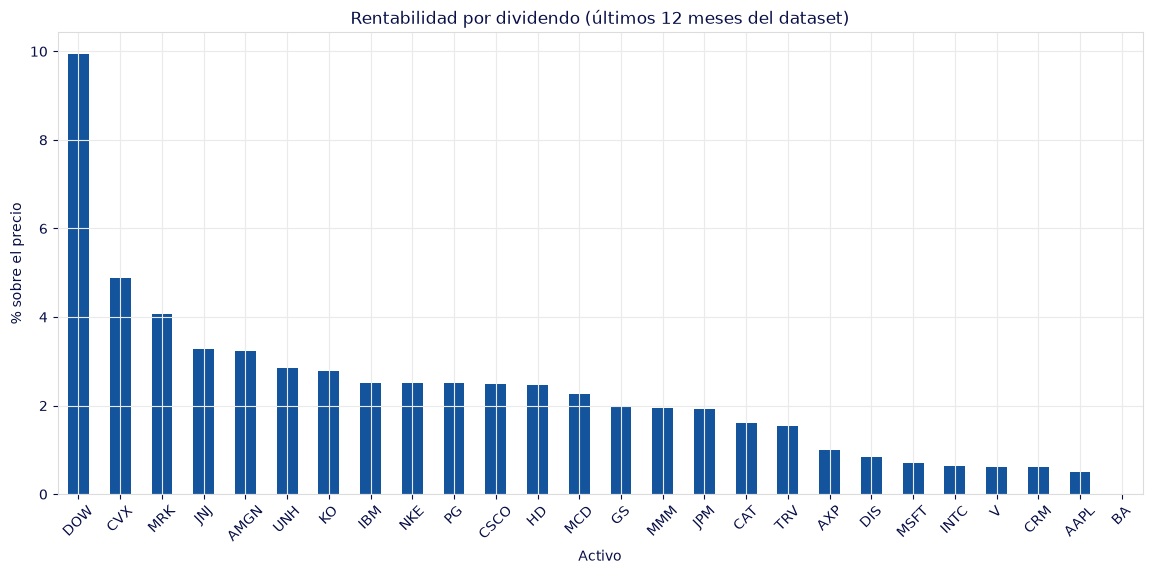

In [140]:
# Rentabilidad por dividendo de cada activo
(tabla_dividendos["Rentab. por dividendo"].sort_values(ascending=False) * 100).plot(kind="bar", figsize=(14, 6), color=paleta_bbva["azul_logotipo"])
plt.title("Rentabilidad por dividendo (últimos 12 meses del dataset)")
plt.xlabel("Activo")
plt.ylabel("% sobre el precio")
plt.xticks(rotation=45)
plt.savefig(os.path.join(ruta_graficos, ('Rentabilidad por dividendo (últimos 12 meses del dataset)' + '.png').replace(' ', '_')))
plt.show()

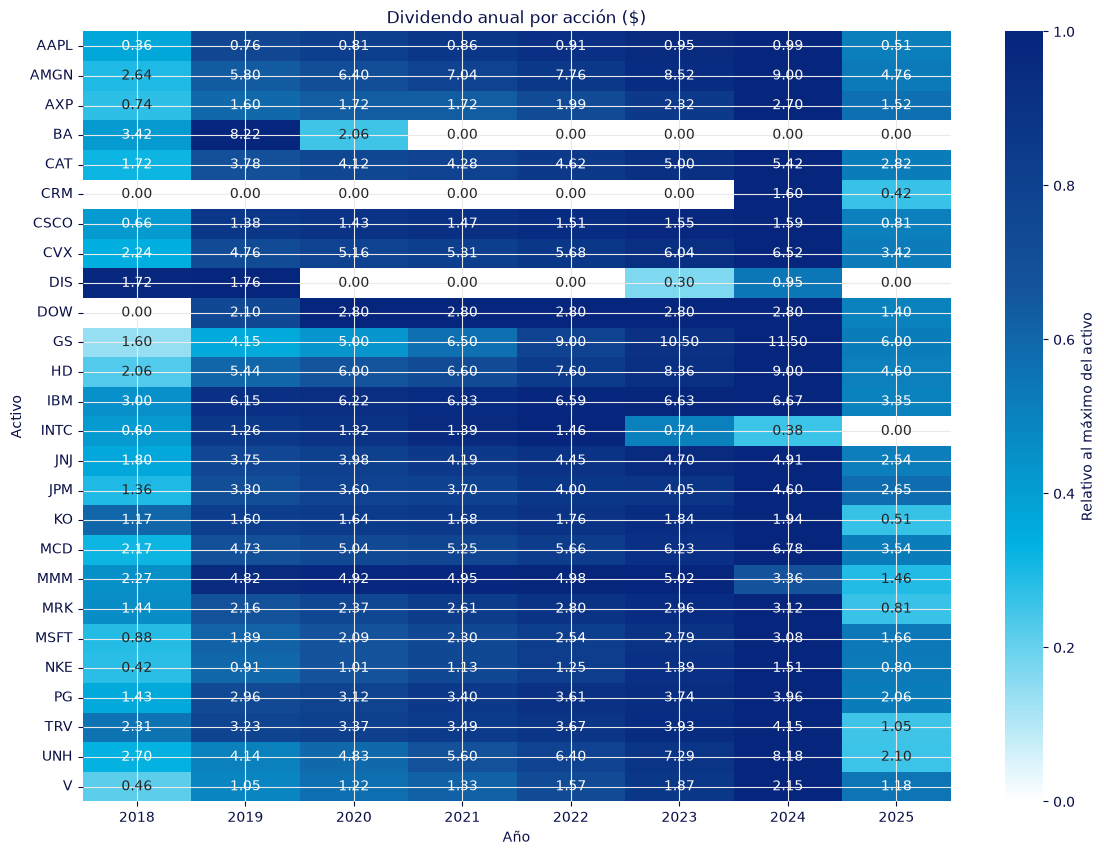

In [141]:
# Evolución del dividendo anual por acción: el color es relativo al máximo de cada activo
# (permite ver de un vistazo recortes, suspensiones y crecimiento); el número es el dividendo en $.
if dividendos:
    anios = list(range(inicio_periodo.year, fin_periodo.year + 1))
    dps_anual = (pd.DataFrame({t: s.groupby(s.index.year).sum() for t, s in dividendos.items()}).reindex(anios).T.reindex(tickers).fillna(0))
    relativo = dps_anual.div(dps_anual.max(axis=1).replace(0, np.nan), axis=0)

    plt.figure(figsize=(14, 10))
    sns.heatmap(relativo, annot=dps_anual, fmt=".2f", cmap=cmap_bbva, cbar_kws={"label": "Relativo al máximo del activo"})
    plt.title("Dividendo anual por acción ($)")
    plt.xlabel("Año")
    plt.ylabel("Activo")
    plt.savefig(os.path.join(ruta_graficos, ('Dividendo anual por acción ($)' + '.png').replace(' ', '_')))
    plt.show()
else:
    print("No se han obtenido dividendos.")

## 17. MÉTRICAS ADICIONALES PARA LA SELECCIÓN DE LOS TRES ACTIVOS

Métricas extra para apoyar la elección de los tres activos:

- **Alpha y Beta** (riesgo de mercado).
- **Deuda** de las empresas.
- **Payout:** % de los beneficios que se destina a dividendos.
- **RSI y MACD** (análisis técnico).
- **Put/Call ratio** (opciones).

Alpha, Beta, RSI y MACD se calculan con el dataset (2018-2025). Deuda, payout y Put/Call son una **foto actual** de `yfinance`.

In [142]:
# Activos para los gráficos de detalle. Mientras no estén elegidos se usan los tres de mayor Sharpe;
activos_seleccion = []
if not activos_seleccion:
    activos_seleccion = tabla_final["Sharpe"].sort_values(ascending=False).head(3).index.tolist()
print("Activos seleccionados:", activos_seleccion)

# Índice de referencia (mercado): Dow Jones, porque los 26 activos del dataset son sus componentes
TICKER_INDICE = "^DJI"
indice = yf.download(TICKER_INDICE, start=inicio_periodo, end=fin_periodo + pd.Timedelta(days=1), auto_adjust=True, progress=False)
precio_indice = sin_zona_horaria(indice["Close"].squeeze())

Activos seleccionados: ['MSFT', 'AAPL', 'V']


### 17.1 Beta y Alpha

$\beta_i = \frac{Cov(r_i, r_m)}{Var(r_m)}$

- $\beta > 1$: el activo amplifica los movimientos del mercado (agresivo); $\beta < 1$: los amortigua (defensivo).
- **Alpha de Jensen:** rentabilidad obtenida por encima (o por debajo) de la que le correspondía por su beta según el CAPM: $\alpha_i = r_i - [r_f + \beta_i (r_m - r_f)]$

In [143]:
# Función para calcular Beta y Alpha frente al índice
def beta_alpha(precio_activo, precio_mercado, rf=0.0, dias_habiles=252):
    df = pd.concat([precio_activo, precio_mercado], axis=1, join="inner").dropna()
    df.columns = ["activo", "mercado"]
    rent = df.pct_change().dropna()
    beta = rent["activo"].cov(rent["mercado"]) / rent["mercado"].var()

    n = len(df)
    rent_activo = rtb_anualizada('d', n, df["activo"].iloc[0], df["activo"].iloc[-1], dias_habiles)
    rent_mercado = rtb_anualizada('d', n, df["mercado"].iloc[0], df["mercado"].iloc[-1], dias_habiles)
    alpha = rent_activo - (rf + beta * (rent_mercado - rf))
    return beta, alpha

filas = {}
for activo in datos.columns:
    serie = datos[activo].copy()
    serie.index = indice_precios
    beta, alpha = beta_alpha(serie, precio_indice, rf)
    filas[activo] = {"Beta": beta, "Alpha (anual)": alpha}

tabla_capm = pd.DataFrame.from_dict(filas, orient="index")
tabla_capm.index.name = "Activo"
tabla_capm.sort_values("Beta", ascending=False).style.format({"Beta": "{:.2f}", "Alpha (anual)": "{:.2%}"})

,Beta,Alpha (anual)
Activo,,
BA,1.39,-18.38%
AXP,1.13,9.33%
DOW,1.10,-12.90%
INTC,1.09,-20.51%
CRM,1.05,2.03%
JPM,1.02,8.40%
AAPL,1.01,15.52%
MSFT,0.97,17.85%
CVX,0.96,-1.59%


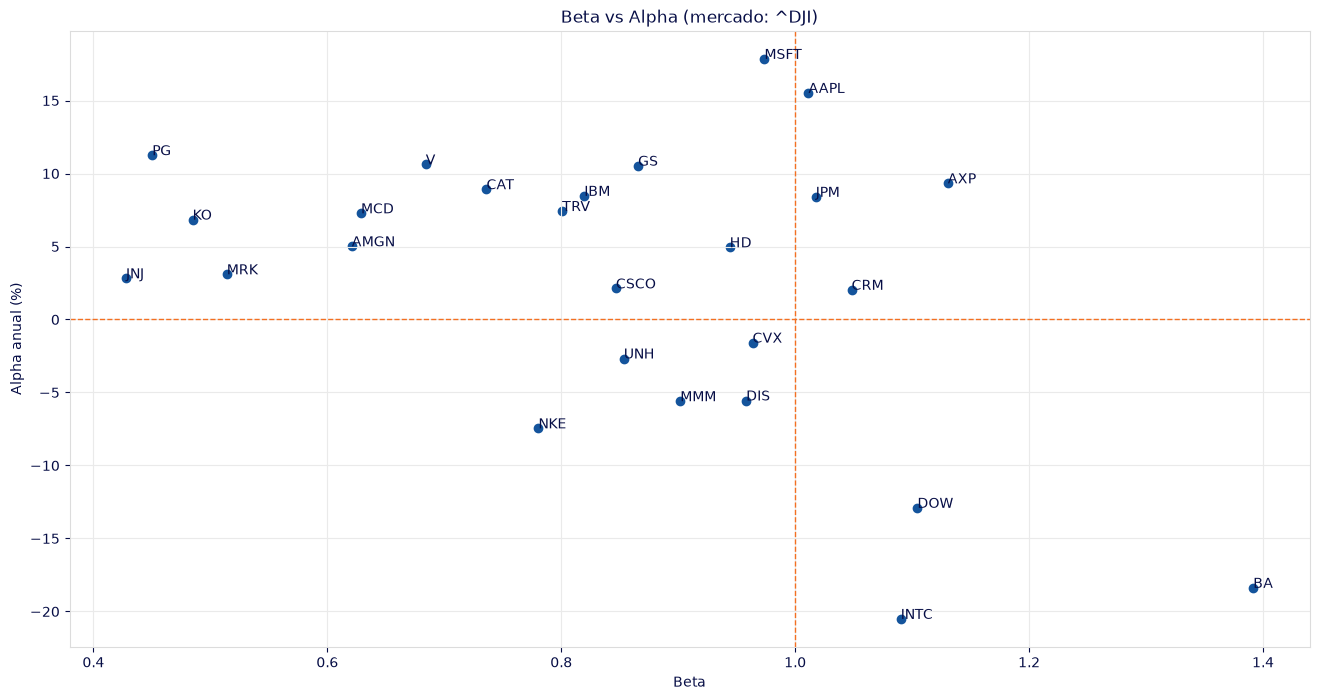

In [144]:
# Beta vs Alpha: arriba a la izquierda, activos que han batido al mercado con poco riesgo sistemático
fig, ax = plt.subplots(figsize=(16, 8))
ax.scatter(tabla_capm["Beta"], tabla_capm["Alpha (anual)"] * 100, color=paleta_bbva["azul_logotipo"])
for activo in tabla_capm.index:
    ax.annotate(activo, (tabla_capm.loc[activo, "Beta"], tabla_capm.loc[activo, "Alpha (anual)"] * 100), color=paleta_bbva["azul_profundo_texto"])

ax.axhline(0, color=paleta_bbva["naranja_alerta"], linestyle="--", linewidth=1)
ax.axvline(1, color=paleta_bbva["naranja_alerta"], linestyle="--", linewidth=1)
plt.title(f"Beta vs Alpha (mercado: {TICKER_INDICE})")
plt.xlabel("Beta")
plt.ylabel("Alpha anual (%)")
plt.show()

### 17.2 Deuda de las empresas

- **Deuda/Patrimonio:** deuda total entre fondos propios. Más de 1 significa que la empresa se financia más con deuda que con capital propio.
- **Deuda neta/EBITDA:** años de beneficio operativo necesarios para pagar la deuda neta (deuda − caja). Por encima de 3 suele considerarse elevado.

**Atención:** en bancos y aseguradoras (JPM, GS, AXP, TRV) la deuda forma parte de su negocio, así que estos ratios no son comparables con los del resto.

In [145]:
# Deuda de cada activo (último balance publicado)
def num(activo, campo):
    return pd.to_numeric(info[activo].get(campo), errors="coerce")

filas = {}
for activo in tickers:
    deuda, caja, ebitda = num(activo, "totalDebt"), num(activo, "totalCash"), num(activo, "ebitda")
    filas[activo] = {"Deuda total ($ miles de millones)": deuda / 1e9,
        "Deuda neta ($ miles de millones)": (deuda - caja) / 1e9,
        "Deuda/Patrimonio": num(activo, "debtToEquity") / 100, 
        "Deuda neta/EBITDA": (deuda - caja) / ebitda if ebitda > 0 else np.nan,}

tabla_deuda = pd.DataFrame.from_dict(filas, orient="index")
tabla_deuda.index.name = "Activo"
tabla_deuda.sort_values("Deuda neta/EBITDA", ascending=False).style.format("{:.2f}", na_rep="-")

,Deuda total ($ miles de millones),Deuda neta ($ miles de millones),Deuda/Patrimonio,Deuda neta/EBITDA
Activo,,,,
BA,48.46,27.79,7.39,13.81
MCD,54.60,53.78,-,3.60
IBM,67.14,56.08,1.85,3.37
DOW,18.97,14.48,1.08,3.21
MRK,53.91,46.77,1.28,2.93
AMGN,57.30,43.31,4.90,2.51
HD,63.19,61.10,3.80,2.48
CRM,42.38,30.97,1.10,2.40
CAT,45.20,38.10,2.10,2.21


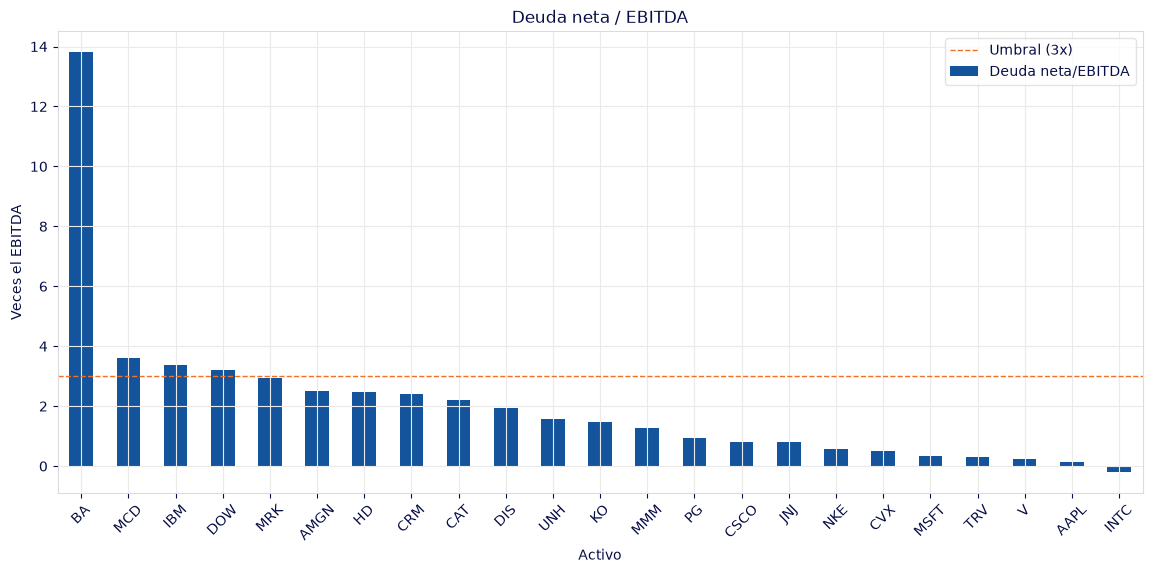

In [146]:
# Deuda neta / EBITDA por activo
tabla_deuda["Deuda neta/EBITDA"].dropna().sort_values(ascending=False).plot(kind="bar", figsize=(14, 6), color=paleta_bbva["azul_logotipo"])
plt.axhline(3, color=paleta_bbva["naranja_alerta"], linestyle="--", linewidth=1, label="Umbral (3x)")
plt.title("Deuda neta / EBITDA")
plt.xlabel("Activo")
plt.ylabel("Veces el EBITDA")
plt.xticks(rotation=45)
plt.legend()
plt.savefig(os.path.join(ruta_graficos, ('Deuda neta EBITDA' + '.png').replace(' ', '_')))
plt.show()

### 17.3 Payout: % de beneficios destinado a dividendos

$Payout = \frac{Dividendo\ por\ acción}{Beneficio\ por\ acción}$

- Payout bajo (< 40 %): la empresa reinvierte la mayor parte del beneficio.
- Payout moderado (40-70 %): reparto equilibrado, típico de empresas maduras.
- Payout > 100 %: reparte más de lo que gana; dividendo difícil de mantener.

In [147]:
# Payout de cada activo
filas = {}
for activo in tickers:
    filas[activo] = {"Dividendo por acción ($)": num(activo, "dividendRate"),
        "Beneficio por acción ($)": num(activo, "trailingEps"),
        "Payout": num(activo, "payoutRatio"),}

tabla_payout = pd.DataFrame.from_dict(filas, orient="index")
tabla_payout.index.name = "Activo"
tabla_payout.sort_values("Payout", ascending=False).style.format({"Dividendo por acción ($)": "{:.2f}", "Beneficio por acción ($)": "{:.2f}", "Payout": "{:.1%}"}, na_rep="-")

,Dividendo por acción ($),Beneficio por acción ($),Payout
Activo,,,
DOW,1.40,-1.28,700.0%
MRK,3.40,0.97,266.7%
JNJ,5.36,6.59,80.1%
NKE,1.64,2.08,78.8%
CVX,7.12,13.47,67.2%
HD,9.32,13.98,64.8%
PG,4.35,6.64,64.6%
KO,2.12,3.35,62.0%
AMGN,10.08,16.10,60.9%


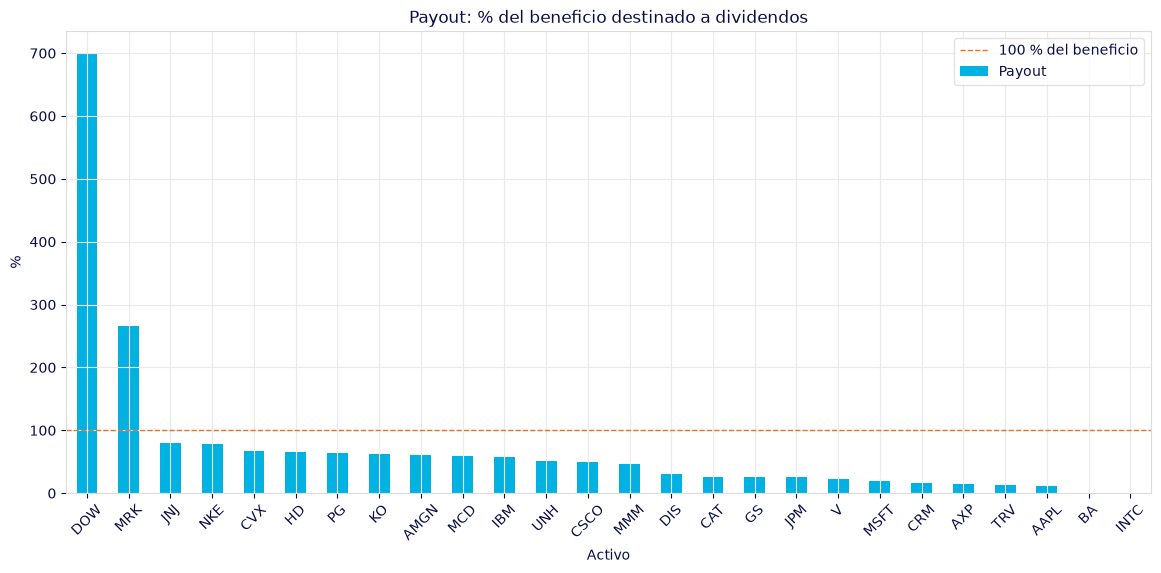

In [148]:
# Payout por activo
(tabla_payout["Payout"].dropna().sort_values(ascending=False) * 100).plot(kind="bar", figsize=(14, 6), color=paleta_bbva["azul_celeste_aqua"])
plt.axhline(100, color=paleta_bbva["naranja_alerta"], linestyle="--", linewidth=1, label="100 % del beneficio")
plt.title("Payout: % del beneficio destinado a dividendos")
plt.xlabel("Activo")
plt.ylabel("%")
plt.xticks(rotation=45)
plt.legend()
plt.savefig(os.path.join(ruta_graficos, ('Payout del beneficio destinado a dividendos' + '.png').replace(' ', '_')))
plt.show()

### 17.4 RSI y MACD

**RSI (14 sesiones):** $RSI = 100 - \frac{100}{1 + RS}$, con $RS = \frac{\text{media de subidas}}{\text{media de bajadas}}$

- RSI > 70: sobrecompra (posible corrección). RSI < 30: sobreventa (posible rebote).

**MACD (12, 26, 9):** línea MACD = EMA12 − EMA26; línea de señal = EMA9 del MACD.

- MACD por encima de la señal: impulso alcista; por debajo: impulso bajista.

In [149]:
#Funciones RSI y MACD
def rsi(precios, periodo=14):
    delta = precios.dropna().diff()
    media_subidas = delta.clip(lower=0).ewm(alpha=1 / periodo, min_periods=periodo, adjust=False).mean()
    media_bajadas = (-delta.clip(upper=0)).ewm(alpha=1 / periodo, min_periods=periodo, adjust=False).mean()
    return 100 - 100 / (1 + media_subidas / media_bajadas)

def macd(precios, rapida=12, lenta=26, senal=9):
    precios = precios.dropna()
    linea_macd = precios.ewm(span=rapida, adjust=False).mean() - precios.ewm(span=lenta, adjust=False).mean()
    linea_senal = linea_macd.ewm(span=senal, adjust=False).mean()
    return linea_macd, linea_senal

#Situación de cada activo en el último día del dataset
filas = {}
for activo in datos.columns:
    ultimo_rsi = rsi(datos[activo]).iloc[-1]
    linea_macd, linea_senal = macd(datos[activo])
    filas[activo] = {"RSI (14)": ultimo_rsi,
        "Situación RSI": "Sobrecompra" if ultimo_rsi > 70 else ("Sobreventa" if ultimo_rsi < 30 else "Neutral"),
        "MACD": linea_macd.iloc[-1],
        "Señal MACD": linea_senal.iloc[-1],
        "Tendencia MACD": "Alcista" if linea_macd.iloc[-1] > linea_senal.iloc[-1] else "Bajista",}

tabla_tecnico = pd.DataFrame.from_dict(filas, orient="index")
tabla_tecnico.index.name = "Activo"
print("Fecha de referencia:", pd.Timestamp(datos.index[-1]).date())
tabla_tecnico.sort_values("RSI (14)", ascending=False).style.format({"RSI (14)": "{:.1f}", "MACD": "{:.2f}", "Señal MACD": "{:.2f}"})

Fecha de referencia: 2025-06-06


,RSI (14),Situación RSI,MACD,Señal MACD,Tendencia MACD
Activo,,,,,
MSFT,73.8,Sobrecompra,13.28,14.46,Bajista
CSCO,68.7,Neutral,1.29,1.29,Bajista
DIS,65.7,Neutral,3.78,4.31,Bajista
BA,65.6,Neutral,7.22,7.92,Bajista
V,64.1,Neutral,5.62,5.73,Bajista
IBM,63.5,Neutral,4.82,4.94,Bajista
GS,60.6,Neutral,12.19,14.21,Bajista
AXP,60.1,Neutral,5.34,6.11,Bajista
CAT,60.0,Neutral,6.84,7.94,Bajista


## cambiar por los tres activos que elijamos

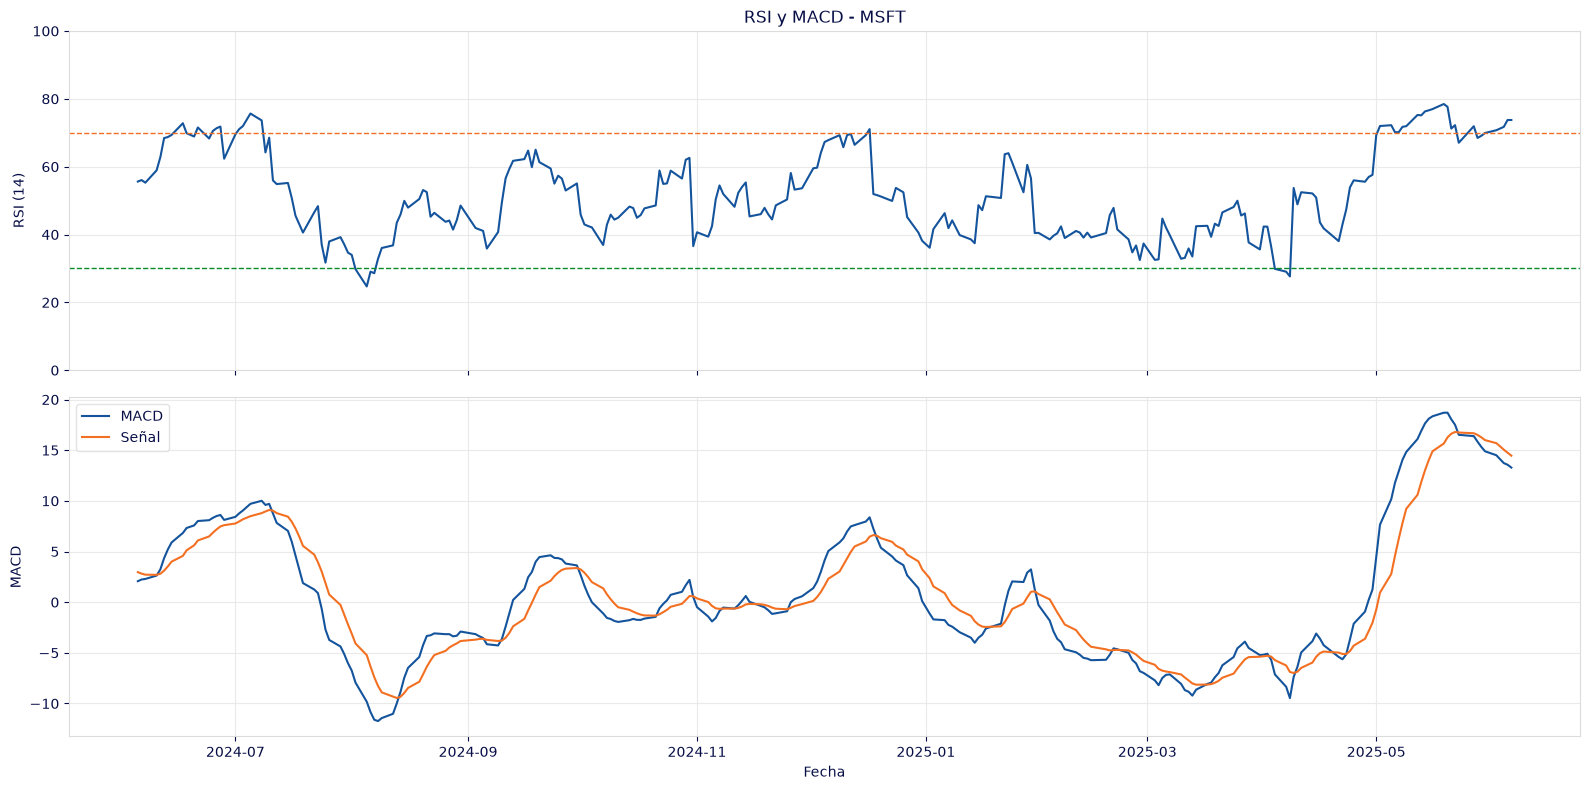

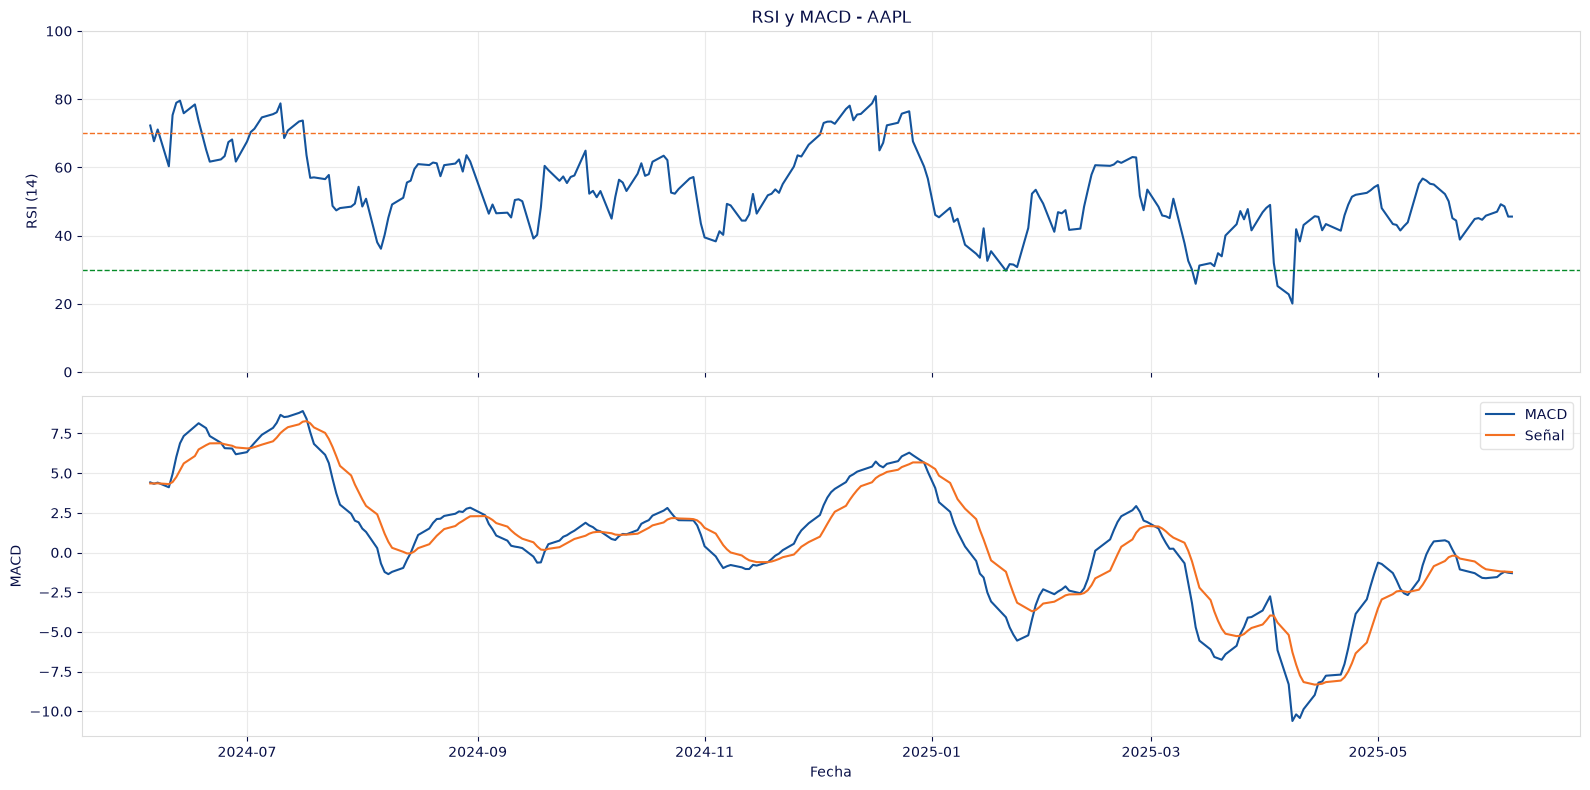

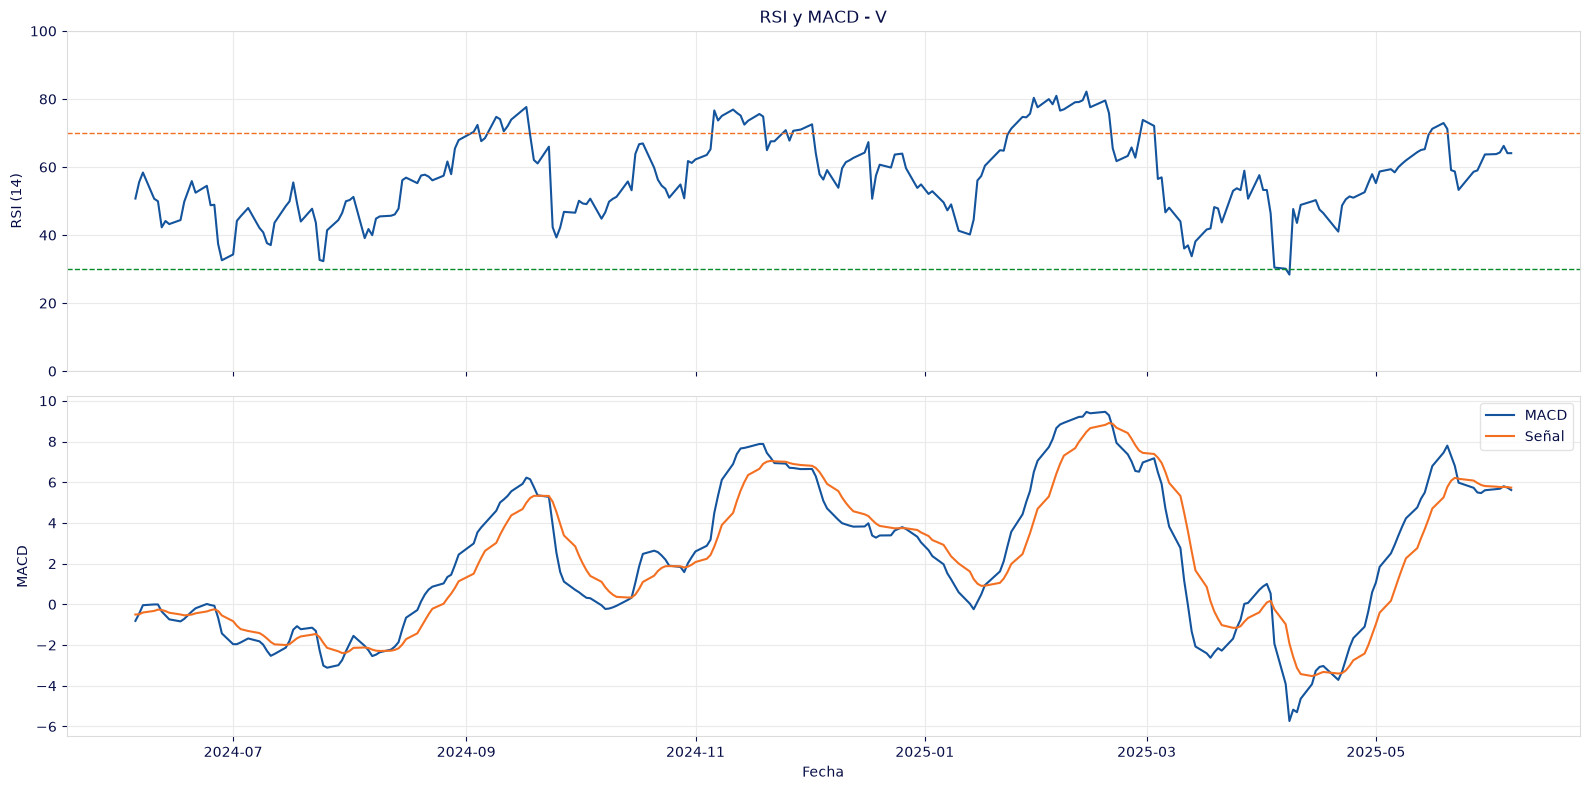

In [150]:
#RSI y MACD de los activos seleccionados (último año del dataset)
for activo in activos_seleccion:
    serie_rsi = rsi(datos[activo]).iloc[-252:]
    linea_macd, linea_senal = macd(datos[activo])
    linea_macd, linea_senal = linea_macd.iloc[-252:], linea_senal.iloc[-252:]

    fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

    axes[0].plot(serie_rsi.index, serie_rsi, color=paleta_bbva["azul_logotipo"])
    axes[0].axhline(70, color=paleta_bbva["naranja_alerta"], linestyle="--", linewidth=1)
    axes[0].axhline(30, color=paleta_bbva["verde_sostenibilidad"], linestyle="--", linewidth=1)
    axes[0].set_ylim(0, 100)
    axes[0].set_title(f"RSI y MACD - {activo}")
    axes[0].set_ylabel("RSI (14)")

    axes[1].plot(linea_macd.index, linea_macd, color=paleta_bbva["azul_logotipo"], label="MACD")
    axes[1].plot(linea_senal.index, linea_senal, color=paleta_bbva["naranja_alerta"], label="Señal")
    axes[1].set_xlabel("Fecha")
    axes[1].set_ylabel("MACD")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(os.path.join(ruta_graficos, (f"RSI y MACD - {activo}" + '.png').replace(' ', '_')))
    plt.show()

### 17.5 Put/Call ratio

Volumen de opciones *put* (cobertura frente a caídas) entre el de opciones *call* (apuestas por subidas), con la cadena de opciones de hoy (`option_chain`):

- < 0,7: sentimiento alcista.
- 0,7 - 1: neutral.
- \> 1: sentimiento bajista o mucha demanda de cobertura.

Se suman los primeros vencimientos disponibles.

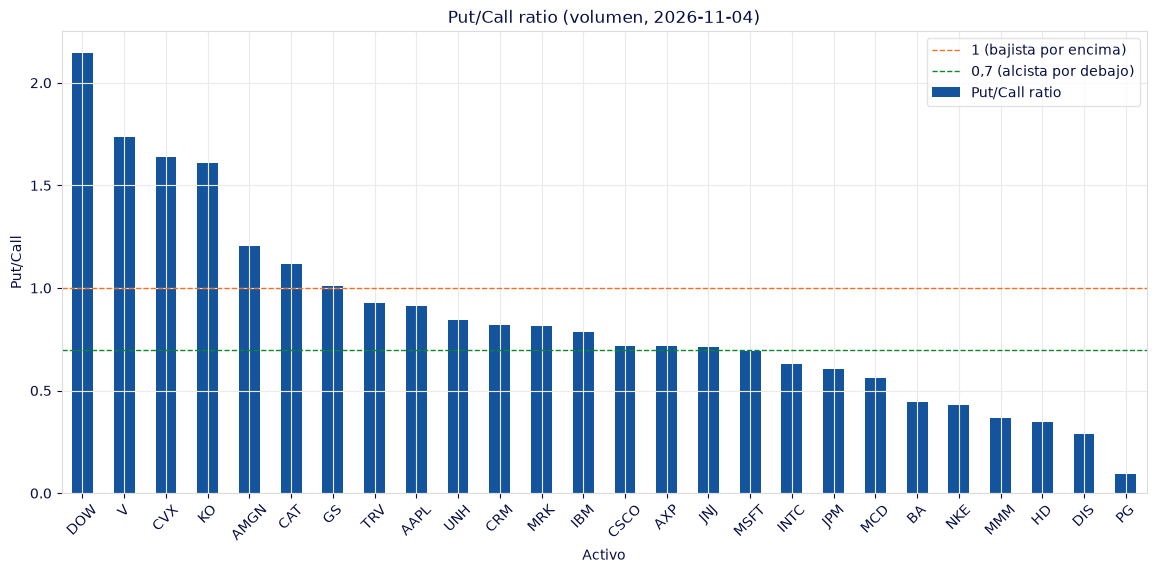

In [154]:
# Put/Call ratio de cada activo (foto actual)
N_VENCIMIENTOS = 4

put_call = {}
for activo in tickers:
    try:
        vol_calls = vol_puts = 0
        for venc in activos_yf[activo].options[:N_VENCIMIENTOS]:
            cadena = activos_yf[activo].option_chain(venc)
            vol_calls += cadena.calls["volume"].fillna(0).sum()
            vol_puts += cadena.puts["volume"].fillna(0).sum()
        put_call[activo] = vol_puts / vol_calls if vol_calls > 0 else np.nan
    except Exception as e:
        print(f"[aviso] {activo}: no se pudieron obtener opciones ({type(e).__name__})")

tabla_put_call = pd.DataFrame.from_dict(put_call, orient="index", columns=["Put/Call ratio"])
tabla_put_call.index.name = "Activo"

tabla_put_call["Put/Call ratio"].dropna().sort_values(ascending=False).plot(kind="bar", figsize=(14, 6), color=paleta_bbva["azul_logotipo"])
plt.axhline(1, color=paleta_bbva["naranja_alerta"], linestyle="--", linewidth=1, label="1 (bajista por encima)")
plt.axhline(0.7, color=paleta_bbva["verde_sostenibilidad"], linestyle="--", linewidth=1, label="0,7 (alcista por debajo)")
plt.title(f"Put/Call ratio (volumen, {pd.Timestamp.today().date()})")
plt.xlabel("Activo")
plt.ylabel("Put/Call")
plt.xticks(rotation=45)
plt.legend()
plt.savefig(os.path.join(ruta_graficos, (f"Put Call ratio volumen {pd.Timestamp.today().date()}" + '.png').replace(' ', '_')))
plt.show()

### 17.6 Tabla todo junto
Unimos las métricas principales con las nuevas para comparar los activos.

In [ ]:
#resumen
tabla_resumen = (tabla_final[["Rentabilidad anualizada", "Volatilidad anualizada", "Sharpe", "Drawdown máximo"]]
    .join(tabla_capm)
    .join(tabla_deuda[["Deuda/Patrimonio", "Deuda neta/EBITDA"]])
    .join(tabla_payout[["Payout"]])
    .join(tabla_tecnico[["RSI (14)", "Tendencia MACD"]])
    .join(tabla_put_call)
    .sort_values("Sharpe", ascending=False))

tabla_resumen.style.format({
    "Rentabilidad anualizada": "{:.2%}", "Volatilidad anualizada": "{:.2%}", "Sharpe": "{:.2f}",
    "Drawdown máximo": "{:.2%}", "Beta": "{:.2f}", "Alpha (anual)": "{:.2%}", "Deuda/Patrimonio": "{:.2f}",
    "Deuda neta/EBITDA": "{:.2f}", "Payout": "{:.1%}", "RSI (14)": "{:.1f}", "Put/Call ratio": "{:.2f}",}, na_rep="-")

,Rentabilidad anualizada,Volatilidad anualizada,Sharpe,Drawdown máximo,Beta,Alpha (anual),Deuda/Patrimonio,Deuda neta/EBITDA,Payout,RSI (14),Tendencia MACD,Put/Call ratio
Activo,,,,,,,,,,,,
MSFT,25.53%,29.30%,0.87,-37.15%,0.97,17.85%,0.28,0.34,19.0%,73.8,Bajista,0.68
AAPL,23.50%,31.67%,0.74,-38.57%,1.01,15.52%,0.71,0.14,11.8%,45.6,Bajista,0.85
V,16.02%,24.88%,0.64,-35.97%,0.68,10.62%,0.61,0.25,22.1%,64.1,Bajista,1.74
PG,14.81%,23.83%,0.62,-23.77%,0.45,11.25%,0.70,0.94,64.6%,45.1,Bajista,0.10
GS,17.37%,30.11%,0.58,-44.79%,0.87,10.53%,7.56,-,25.9%,60.6,Bajista,1.09
AXP,18.25%,34.30%,0.53,-49.64%,1.13,9.33%,1.68,-,15.3%,60.1,Bajista,0.73
JPM,16.44%,31.93%,0.51,-43.63%,1.02,8.40%,-,-,25.8%,55.9,Bajista,0.59
MCD,12.24%,24.24%,0.50,-36.90%,0.63,7.27%,-,3.60,59.7%,44.6,Bajista,0.54
KO,10.67%,21.87%,0.49,-36.99%,0.48,6.84%,1.07,1.48,62.0%,46.7,Bajista,1.72
